# 20 · Convergence with the number of skewers (TNG50-2, the `skewers` sweep)


How many skewers are needed? Five nested lattices of the fiducial dataset (TNG50-2 snapshot 25, along $y$, 1 km/s, the
exact crossings, the integrated profile, the exact frame), $N \times N$ = $32^2$, $64^2$, $128^2$ (the fiducial), $256^2$ and
$512^2$ skewers at $x_i = i\,L/N$: every coarser lattice is a subset of the finer ones, read from **one** dataset of the
campaign's store (the $512^2$ lattice extended the fiducial's $128^2$; `run_production.py --sweep skewers`). The reference is
$512^2$. The difference of a coarser lattice is its **sample variance** and its aliasing: the same skewers, fewer of them,
and a lower transverse Nyquist frequency $\pi N/L$ for $P(k, \mu)$. The jackknife squares are the same regions of the
box for every lattice, so the error of the ratio counts the variance the lattices share.

**Memory.** The $512^2$ lattice holds $2 \times 262{,}144 \times 3{,}949$ pixels (8.3 GB of $\tau$); its 3D bins and transforms take
about 40 GB at peak and the run about 20 minutes (Part B gives the time of each step).


Every run is a folder of `scripts/production/run_production.py` (`<OUT>/<SWEEP>/<run>/run.json`) that names its
lattice in the campaign's skewer store; `load_run` reads it. The statistics follow notebooks 11 and 18 on **one line of
sight** ($y$): the transmission $T = e^{-\tau}$ of every line and of the total, its mean $\bar T$, the overflux
$\delta = T/\bar T - 1$, P1D on its native modes and $P(k, \mu)$ of the total in four wedges, and both split
order by order and term by term on the 16 wedges of notebook 11 (`summary_stats.run_statistics`). One line of sight gives no ensemble, so the errors come from a **delete-one-block
jackknife**: the lattice is cut into $4 \times 4$ squares of skewers and each sample leaves one square out (the
3D power of the field with that square set to zero, divided by the fraction kept). Every run is compared with the
reference **bin by bin**, as the relative difference $X_{\rm run}/X_{\rm ref} - 1$, with the jackknife error of that
ratio (`compare_runs`): the runs share the skewer positions and the blocks, so the sample variance they share cancels.
The last part gives, per run, **the largest $k$ up to which every bin differs by less than 0.1%, 0.5% and 1%**
(`k_max_table`; P1D on every native mode, $P(k, \mu)$ on every $|k|$ bin).

Colours: the fiducial run of the campaign in black in every notebook; the other runs from light (coarse) to dark (fine)
on one scale shared by notebooks 18–21.


- **Part A — the stored skewers read back:** every run's lattice, pixels, sampling and dataset, and the checks of the
  pairing (every lattice the stride of the largest, bit for bit).
- **Part B — the statistics of every run** and their comparison with the reference.
- **Part C — the mean transmission.**
- **Part D — P1D by order and by term:** D1 the total and orders 2–4, D2 the order-2 terms (the autos of
  $\mathrm{Ly}\alpha$ and Si III, their cross), every run against the $512^2$ lattice.
- **Part E — $P(k, \mu)$ by order and by term in 16 wedges:** E1 the total and orders 2–4, E2 the order-2 terms,
  one figure each.
- **Part F — the converged range:** the largest $k$ within 0.1%, 0.5% and 1% of the reference, and what it implies.

In [1]:
import os
from pathlib import Path

# ---- configuration: the sweep (scripts/production/run_production.py --sweep skewers)
SWEEP = "skewers"
RUNS = ["n_0032", "n_0064", "n_0128", "n_0256", "n_0512"]   # coarse to fine
REFERENCE = "n_0512"                              # the largest lattice: the reference
FIDUCIAL = "n_0128"                               # the fiducial run (black in every figure)
TERMS_REF = REFERENCE                             # the reference of Parts D and E: the largest lattice
ORDER = RUNS
NSK = {"n_0032": 32, "n_0064": 64, "n_0128": 128, "n_0256": 256, "n_0512": 512}
RUN_LABELS = {r: f"{n}$^2$" for r, n in NSK.items()}
TITLE_STEM = "Number of skewers"
LINTHRESH = 0.01                                  # [%]
OUT = Path(os.environ.get("SKEWERJAX_PRODUCTION", Path.home() / "skewerjax_production"))   # the --out of the campaign
N_SUB = None                                      # None: each run's lattice; 32: a quick check on the nested 32^2 sub-lattice
N_BLOCKS = 4                                      # jackknife: N_BLOCKS x N_BLOCKS squares of skewers
MU_EDGES = (0.0, 0.5, 0.8, 0.95, 1.0)             # the four wedges of P(k, mu) (notebooks 10 and 11's wedges of xi)
TOLS = (0.001, 0.005, 0.01)                       # the convergence levels of Part F
N_MU_TERMS = 16                                   # Parts D and E: the wedges of notebook 11, even in the angle to the line of sight
RES_LINTHRESH = 1.0                               # [%]: the residual rows of Parts D and E are linear within it
X_OF_RUN, X_LABEL, X_SCALE, X_TICKS = {r: n * n for r, n in NSK.items()}, "skewers $N^2$", "log", None

# ---- imports
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import json, sys, time
import numpy as np
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import (TERM_ORDERS, add_panel_letters, field_names, order2_terms, run_styles,
                                      plot_runs_mean_flux, plot_runs_p1d_orders, plot_runs_p1d_terms, plot_runs_pk_mu_orders,
                                      plot_runs_pk_mu_terms, plot_k_max_summary)
from skewerjax.summary_stats import (LatticeWedges, block_labels, compare_runs, format_k_max_table, format_terms_table,
                                     k_max_table, rebin_pixels, run_statistics, set_k_edges)
from skewerjax.utils.reference_data import P1D_DESI_DR1, nearest_reference
from skewerjax.utils.paths import PRODUCTION_DIR, PRODUCTION_SCRIPTS_DIR   # the run folders; the reader of the skewer store
sys.path.insert(0, str(PRODUCTION_SCRIPTS_DIR))
from skewer_store import load_run
from skewerjax.utils.plotting import PALETTE

## Part A — The stored skewers read back

- `OUT`, `SWEEP`, `RUNS`: the run folders `<OUT>/<SWEEP>/<run>`, each one lattice of the same dataset.
- `N_SUB` must stay `None` here (the lattices are the sweep).

The check of the nesting: every lattice read back is, skewer by skewer and bit for bit, the stride $512/N$ of the $512^2$
lattice (the same skewers are stored once and read by every lattice).

In [2]:
RECS = {r: json.loads((OUT / SWEEP / r / "run.json").read_text()) for r in RUNS}
S = {r: load_run(OUT / SWEEP / r, N_SUB) for r in RUNS}          # tau (n_lines, N_sk, N_pix), positions, columns, v, dv, L, u
REF = S[REFERENCE]
L, U, PERIOD = REF.L, REF.u, REF.period                          # [cMpc], aH [km/s per cMpc], v_per [km/s]
N = REF.n_per_axis
Z, A_SNAP = RECS[REFERENCE]["snapshot"]["redshift"], RECS[REFERENCE]["snapshot"]["a"]
LINE_IDS = REF.line_ids
FIELDS = (*LINE_IDS, "total")
NAMES = field_names(FIELDS)
print(f"{'run':<13} {'sim':<8} {'lattice':>8} {'N_pix':>6} {'dv [km/s]':>10} {'dx [cMpc]':>10} {'dx [km/s]':>10} {'route':<10} "
      f"{'dataset':<11} {'computed':>8} {'wall':>8}")
for r in RUNS:
    rec, s, sm = RECS[r], S[r], RECS[r]["sampling"]
    print(f"{r:<13} {s.sim:<8} {s.n_per_axis:>5}^2 {s.v.size:>6} {s.dv:>10.4f} {sm['points_cMpc']:>10.3g} {sm['points_kms']:>10.3g} "
          f"{sm['route']:<10} {rec['dataset']['hash']:<11} {rec['timings']['computed']:>8} {rec['wall_s']:>7.0f}s")
    assert np.isfinite(s.tau).all(), r
for r in RUNS:                                    # tau < 0: the round-off of the engine (float32), relative to each skewer's peak
    t = S[r].tau
    neg = t < 0
    if neg.any():
        worst = (-t.min(axis=-1) / t.max(axis=-1)).max(axis=-1)       # (n_lines,) the largest |tau_min| / tau_max of a skewer
        print(f"{r}: tau < 0 in {neg.mean():.2%} of the samples (" + ", ".join(
              f"{NAMES[l]}: min {t[j].min():.2g}, |min| / max per skewer <= {worst[j]:.1e}" for j, l in enumerate(LINE_IDS) if t[j].min() < 0) + ")")
print(f"\nreference {REFERENCE}: {REF.sim} snapshot {REF.snap}, z = {Z:.4f}, L = {L:.3f} cMpc, u = {U:.3f} km/s per cMpc (1 km/s = {1 / U:.5f} cMpc), "
      f"v_per = {PERIOD:.2f} km/s; tau finite in every run")
print("sampling of the reference: " + RECS[REFERENCE]["sampling"]["effect"])

assert len({RECS[r]["dataset"]["hash"] for r in RUNS}) == 1, "every lattice must come from one dataset"
key = {tuple(c): i for i, c in enumerate(REF.columns.tolist())}
for r in RUNS:
    st = S[r].n_per_axis
    idx = [key[(a * (N // st), b * (N // st))] for a, b in S[r].columns.tolist()]
    assert np.array_equal(S[r].tau, REF.tau[:, idx]) and np.array_equal(S[r].positions, REF.positions[idx]), r
print(f"every lattice is the stride of the {N}^2 lattice, bit for bit (dataset {RECS[REFERENCE]['dataset']['hash']})")

run           sim       lattice  N_pix  dv [km/s]  dx [cMpc]  dx [km/s] route      dataset     computed     wall
n_0032        TNG50-2     32^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s
n_0064        TNG50-2     64^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s
n_0128        TNG50-2    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s
n_0256        TNG50-2    256^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9     49152     418s
n_0512        TNG50-2    512^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9    196608    1133s

reference n_0512: TNG50-2 snapshot 25, z = 3.0081, L = 51.668 cMpc, u = 76.673 km/s per cMpc (1 km/s = 0.01304 cMpc), v_per = 3949.82 km/s; tau finite in every run
sampling of the reference: the a(s) table of the exact frame every 0.05 cMpc; not the pieces (the exact cell crossings need no sampling points)
every lattice is t

## Part B — The statistics of every run

The 3D bins are set by the largest lattice (a coarser one is cut at its own Nyquist frequency $\pi N/L$): $|k|$ one bin per mode up to $3.5\,k_f$, steps of $0.4\,k_f$
to 2 cMpc$^{-1}$, then 12 logarithmic bins to the transverse Nyquist frequency $\pi N/L$; the four wedges of
`MU_EDGES` in $\mu = k_\parallel/|k|$. P1D stays on its native modes $k_m = 2\pi m/v_{\rm per}$ for the checks, and is
averaged in 40 logarithmic bins for the figures only. Each line gives the time of each step of a run.

**The decomposition of Parts D and E:** `run_statistics(terms_grid=)` also splits P1D and $P(k, \mu)$ of the total
into its orders and order-2 terms, with the same jackknife, in the 16 wedges of `MU_EDGES_TERMS` on the same $|k|$
bins (`LatticeWedges(store_index=False)`: the transforms along the line of sight first, then across the lattice one
slab of $k_\parallel$ at a time). Two checks are printed per run: the sum of the orders against the total (the sum
rule), and the total against P1D and the four wedges of $P(k, \mu)$ above (the largest difference relative to the
largest value).

In [3]:
KF = 2 * np.pi / L
K_NYQ = np.pi * N / L                                            # the transverse Nyquist frequency of the lattice [1/cMpc]
K_EDGES = set_k_edges(KF, k_1=3.5 * KF, k_2=min(2.0, K_NYQ), k_max=K_NYQ, dk_factor=0.4, n_log=12)
K1D_EDGES = np.geomspace(2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in RUNS), 41)   # display bins of P1D [s/km]
P1D_REF = nearest_reference(P1D_DESI_DR1, Z)
K_DESI = float(np.max(P1D_REF["k"]))                             # [s/km]: the largest k of DESI DR1 at the snapshot's z
MU_EDGES_TERMS = np.sin(np.linspace(0.0, np.pi / 2, N_MU_TERMS + 1))   # the wedges of Parts D and E
GRIDS = {}


def grid_for(n, n_pix):
    """The mu wedges of P on an n x n lattice of n_pix pixels (LatticeWedges: the bins of lattice_grid's P_mu alone, the memory of
    512^2 lattices), cached: the same |k| edges and mu wedges for every run."""
    if (n, n_pix) not in GRIDS:
        GRIDS[n, n_pix] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES)
    return GRIDS[n, n_pix]


def terms_grid_for(n, n_pix):
    """The 16 wedges of the decomposition (Parts D and E), without an index (streamed by run_statistics)."""
    if (n, n_pix, "terms") not in GRIDS:
        GRIDS[n, n_pix, "terms"] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES_TERMS, store_index=False)
    return GRIDS[n, n_pix, "terms"]


def statistics(s, transmissions=None, n_pix=None, dv=None, decompose=True):
    """run_statistics of one run (or of ``transmissions`` on ``n_pix`` pixels of ``dv``) on its lattice's jackknife blocks
    and bins, T_bar the mean over every pixel (one scale factor: the box), with the time of each step; with its
    decomposition by order and term on the 16 wedges (decompose=False: the total alone)."""
    n_pix = s.v.size if n_pix is None else n_pix
    steps = []
    out = run_statistics(None if transmissions is not None else s.tau, s.dv if dv is None else dv, line_ids=LINE_IDS,
                         labels=block_labels(s.columns, s.n_per_axis, N_BLOCKS), grid=grid_for(s.n_per_axis, n_pix),
                         transmissions=transmissions, a_pix=np.full(n_pix, A_SNAP), log=steps.append,
                         terms_grid=terms_grid_for(s.n_per_axis, n_pix), decompose=decompose)
    return out, steps


STATS, T0 = {}, time.perf_counter()
for r in RUNS:
    t = time.perf_counter()
    STATS[r], steps = statistics(S[r])
    print(f"{r:<13} {time.perf_counter() - t:6.1f} s: " + "; ".join(steps))
    tr = STATS[r]["terms"]
    print(f"{'':<13} sum of the orders vs the total: P1D {tr['sum_rule']['p1d']:.1e}, P(k, mu) {tr['sum_rule']['P_mu']:.1e}; "
          f"the total vs P1D and the 4 wedges above: {tr['check']['p1d']:.1e}, {tr['check']['P_mu']:.1e}")
CMP = {r: compare_runs(STATS[r], STATS[REFERENCE], k_edges_1d=K1D_EDGES) for r in RUNS if r != REFERENCE}   # display bins
CMP_ALL = {r: compare_runs(STATS[r], STATS[REFERENCE]) for r in RUNS if r != REFERENCE}                  # every mode: the checks
STYLES = run_styles(ORDER, fiducial=FIDUCIAL)
CMP_T = CMP                                                      # Parts D and E: against TERMS_REF
print(f"every run in {time.perf_counter() - T0:.0f} s; P(k, mu) in {len(MU_EDGES) - 1} wedges x {len(K_EDGES) - 1} |k| bins up to "
      f"{K_NYQ:.2f} cMpc^-1; jackknife over {N_BLOCKS} x {N_BLOCKS} squares of {N // N_BLOCKS} x {N // N_BLOCKS} skewers")
TERMS = order2_terms(CMP_T)                                      # the order-2 terms of D2 and E2: the autos, the cross
K_LIMITS_T = (2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in CMP_T))   # [s/km]: the P1D range the runs share with TERMS_REF


n_0032           3.5 s: transmissions of 1,024 skewers x 3949 pixels (0.1 s); P1D of HI-LyA (0.1 s); P1D of SiIII-1206 (0.1 s); P1D of total (0.1 s); P(k, mu) of total and its 16 jackknife samples (0.5 s); the transforms along the line of sight and P1D of 11 pairs (0.8 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 514 k_par (1.8 s)
              sum of the orders vs the total: P1D 2.0e-09, P(k, mu) 5.1e-08; the total vs P1D and the 4 wedges above: 3.6e-16, 5.9e-08
n_0064           9.1 s: transmissions of 4,096 skewers x 3949 pixels (0.3 s); P1D of HI-LyA (0.4 s); P1D of SiIII-1206 (0.4 s); P1D of total (0.3 s); P(k, mu) of total and its 16 jackknife samples (1.8 s); the transforms along the line of sight and P1D of 11 pairs (2.8 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 128 k_par (2.6 s)
              sum of the orders vs the total: P1D 1.7e-09, P(k, mu) 1.7e-07; the total vs P1D and the 4 wedges above: 3.5e-16, 1.2e-07
n_0128          31

## Part C — The mean transmission

$\bar F$ of every line and of the total, per run, as $100\,(\bar F_{\rm run}/\bar F_{\rm ref} - 1)$ [%] with its
jackknife error (the reference is the line at 0; the grey band is $\pm 0.5\%$, the dotted lines $\pm 0.1\%$ and
$\pm 1\%$; the axis is linear within `LINTHRESH`).

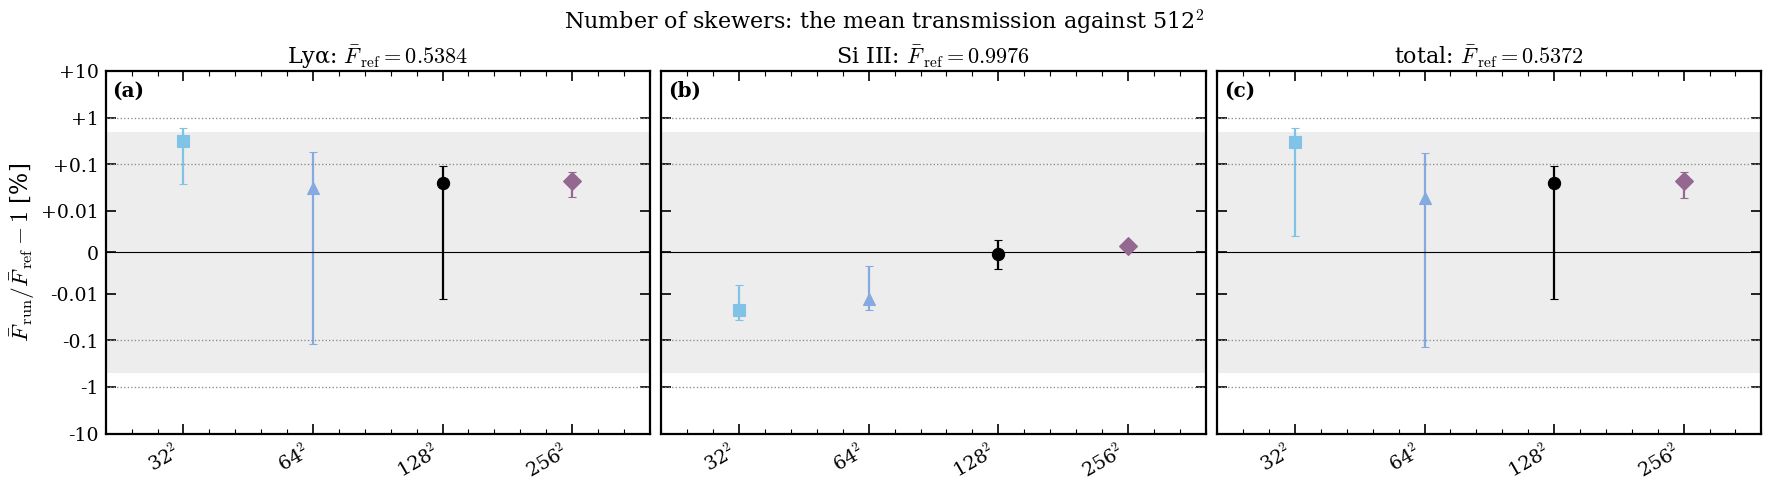

n_0032        Lyα: +0.32 +- 0.28 %; Si III: -0.0223 +- 0.014 %; total: +0.293 +- 0.29 %
n_0064        Lyα: +0.0303 +- 0.15 %; Si III: -0.0127 +- 0.0094 %; total: +0.0193 +- 0.16 %
n_0128        Lyα: +0.0399 +- 0.053 %; Si III: -0.000524 +- 0.0035 %; total: +0.0402 +- 0.053 %
n_0256        Lyα: +0.0438 +- 0.024 %; Si III: +0.00147 +- 0.001 %; total: +0.0438 +- 0.025 %


In [4]:
fig, axs = plot_runs_mean_flux(CMP, STYLES, REFERENCE, field_labels=NAMES, labels=RUN_LABELS, linthresh=LINTHRESH,
                               title=f"{TITLE_STEM}: the mean transmission against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()
for r, c in CMP_ALL.items():
    print(f"{r:<13} " + "; ".join(f"{NAMES[f]}: {100 * c['mean_flux']['rel'][j]:+.3g} +- {100 * c['mean_flux']['err'][j]:.2g} %"
                                  for j, f in enumerate(FIELDS)))

## Part D — P1D by order and by term

**The orders and the terms** (notebook 11, Parts E and F; `docs/decomposition.md`). With $\delta_j = T_j/\bar T_j - 1$
the overflux of line $j$ and $\mathcal C = \bar T/\prod_j \bar T_j - 1$, the total overflux is exactly a sum of subset
fields, $\delta_{\rm tot} = \sum_A F_A$, with $F_\emptyset = -\mathcal C/(1+\mathcal C)$ and
$F_A = \prod_{j\in A}\delta_j/(1+\mathcal C)$. Every two-point statistic of the total is then the sum of the
cross-statistics of the pairs $(A, B)$, grouped by the order $n = |A| + |B| = 0, \dots, 4$ for two lines:

* **order 2:** the $\mathrm{Ly}\alpha$ auto ($F_{\rm Ly\alpha}$ with itself), the Si III auto, their cross
  ($2\,\mathrm{Re}\,P_{\rm Ly\alpha, Si\,III}$, which oscillates as $\cos(k_\parallel \Delta v)$ with the separation
  $\Delta v$ of the lines) and a $\mathcal C$ term;
* **order 3:** each line with the product of the two; **order 4:** the product with itself.

**Orders 0 and 1 are not shown.** They hold only the $\mathcal C$ terms, the corrections of the mean, which vanish on
average. In one snapshot $\mathcal C$ is a single number (`MEAN = "redshift"` with one $a$), so $F_\emptyset$ is a
constant whose power lives at $k = 0$ alone, which P1D at $k > 0$ and $P(k, \mu)$ leave out; the $\mathcal C$ term of
order 2 vanishes alike. At every $k > 0$: total = order 2 + order 3 + order 4 (the sum rule printed in Part B).

**The figures.** Every run against **the $512^2$ lattice** (the highest level of the sweep), drawn thick and light underneath with
its jackknife error as a faint band. Above, $kP_{\rm 1D}/\pi$ in 40 logarithmic display bins. Below, the difference
$\Delta = X_{\rm run} - X_{\rm ref}$ in per cent of $|X_{\rm ref}|$, on the grey band of the reference's jackknife error:
a residual inside the band is not significant. The residual axis is symmetric-log, linear within `RES_LINTHRESH`. A
quantity that changes sign (the cross term, order 3) has a symmetric-log main axis, and where $|X_{\rm ref}|$ falls
below 1% of its maximum in the panel, $\Delta$ is divided by the local envelope of $|X_{\rm ref}|$ instead (its running
maximum over $\pm 2$ bins; open markers). The grey bands lie outside $[2\pi/v_{\rm per}, \pi/dv]$; the dashed line is the
largest $k$ of DESI DR1 at the snapshot's redshift. The tables list, per run and quantity for $k \le k_{\rm DESI}$, the median and largest $|\Delta|$, the median error of the reference, and the share of bins
outside it.

### D1 · P1D by order

The total and orders 2, 3, 4.

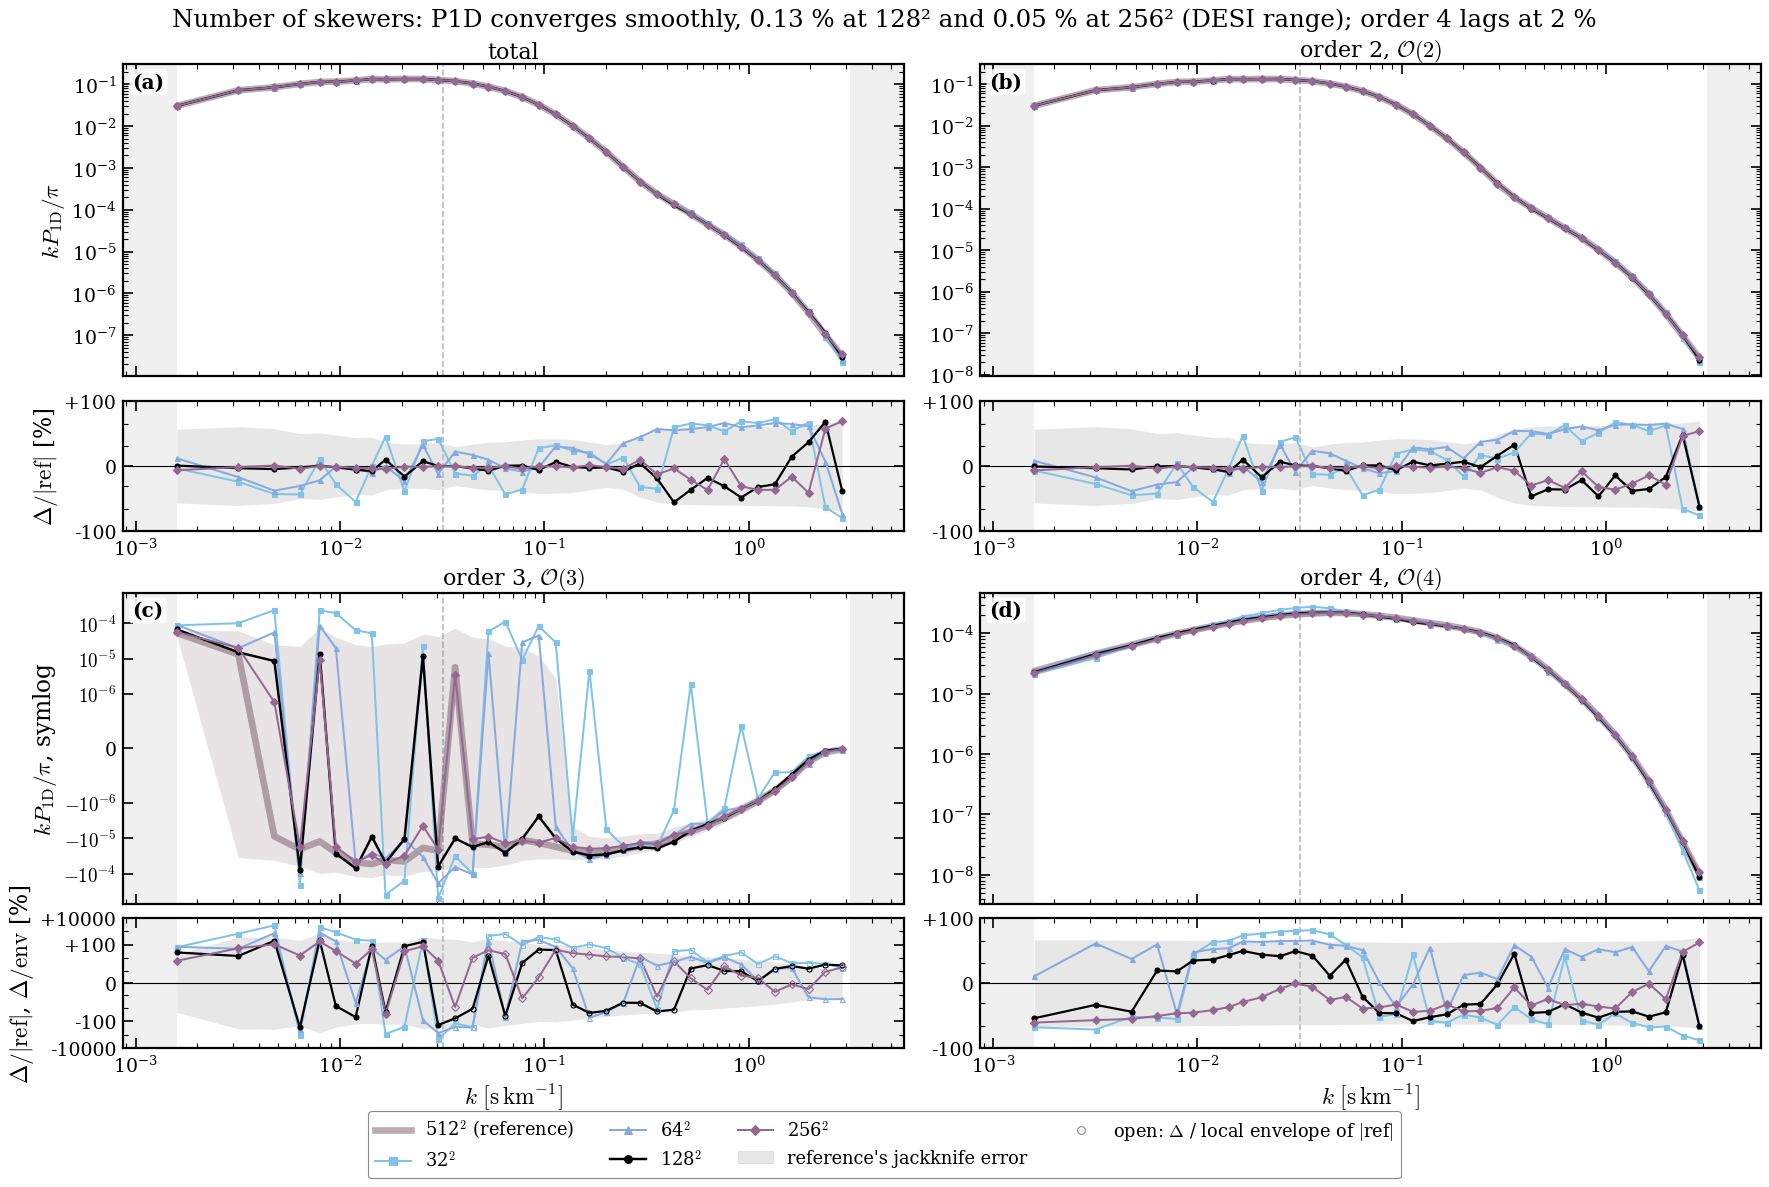

k <= 0.032 s/km, against n_0512:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         total                                  1.65         5.04        2.81      42%
n_0032         order 2                                1.59         5.14        2.82      42%
n_0032         order 3                                 773     2.82e+03         236      92%
n_0032         order 4                                10.9         27.1        10.1      50%
n_0064         total                                 0.477         1.61        2.81       0%
n_0064         order 2                                0.46         1.69        2.82       0%
n_0064         order 3                                77.9          815         236      42%
n_0064         order 4                                5.67         9.66        10.1      17%
n_0128         total                                 0.129        0.526        2.81       0%
n_0128         order 2               

In [5]:
fig, main, res = plot_runs_p1d_orders(CMP_T, STYLES, TERMS_REF, line_ids=LINE_IDS, labels=RUN_LABELS, linthresh=RES_LINTHRESH,
                                      k_limits=K_LIMITS_T, k_mark=K_DESI,
                                      title='Number of skewers: P1D converges smoothly, 0.13 % at 128² and 0.05 % at 256² (DESI range); order 4 lags at 2 %')
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERM_ORDERS, "p1d", k_max=K_DESI))

*Reading.* The nested lattices differ from $512^2$ by sample variance. In the DESI range the total
(and order 2, which carries it) differs by a median 1.7, 0.48, 0.13 and 0.047% at $32^2$, $64^2$, $128^2$ and $256^2$;
from $64^2$ on, inside the 2.8% error of $512^2$. Order 4 converges more slowly: 11, 5.7, 2.2 and 2.4%, against a 10%
error. Order 3 is noise at every $N$ (errors of $\sim 240$% of its envelope).

### D2 · P1D term by term (order 2)

The $\mathrm{Ly}\alpha$ auto, the Si III auto and their cross term.

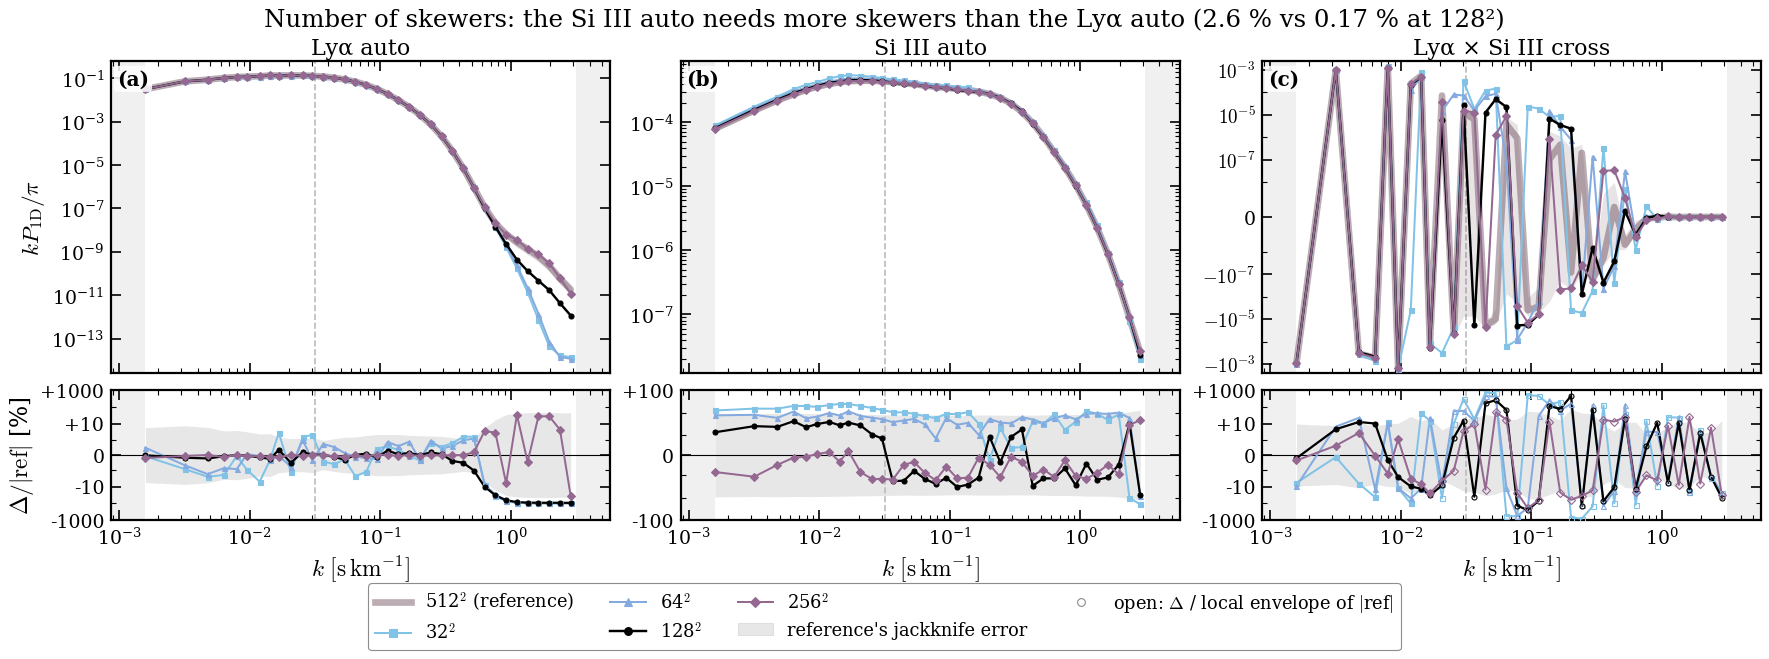

k <= 0.032 s/km, against n_0512:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         HI-LyA|HI-LyA                          1.45         5.03        2.82      42%
n_0032         SiIII-1206|SiIII-1206                  18.8         24.3        8.95     100%
n_0032         HI-LyA|SiIII-1206                        14          297        10.1      67%
n_0064         HI-LyA|HI-LyA                         0.591         1.79        2.82       0%
n_0064         SiIII-1206|SiIII-1206                  7.28         11.4        8.95      25%
n_0064         HI-LyA|SiIII-1206                      13.9         57.8        10.1      75%
n_0128         HI-LyA|HI-LyA                         0.168        0.517        2.82       0%
n_0128         SiIII-1206|SiIII-1206                   2.6         4.15        8.95       0%
n_0128         HI-LyA|SiIII-1206                      9.03         33.6        10.1      33%
n_0256         HI-LyA|HI-LyA         

In [6]:
fig, main, res = plot_runs_p1d_terms(CMP_T, STYLES, TERMS_REF, terms=TERMS, line_ids=LINE_IDS, labels=RUN_LABELS,
                                     linthresh=RES_LINTHRESH, k_limits=K_LIMITS_T,
                                     k_mark=K_DESI, title="Number of skewers: the Si III auto needs more skewers than the Lyα auto (2.6 % vs 0.17 % at 128²)")
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERMS, "p1d", k_max=K_DESI))

*Reading.* In the DESI range the $\mathrm{Ly}\alpha$ auto follows the total (1.5 to 0.06%). The Si III auto
lies 10–20% above $512^2$ at $32^2$ and $64^2$, outside its 9% error, then 2.6% at $128^2$ and 0.4% at $256^2$; the cross
14% to 2.2% of its envelope. Above 0.7 s/km the $\mathrm{Ly}\alpha$ auto of $32^2$–$128^2$ falls about 100 times below
$256^2$ and $512^2$: the heavy tail of a few strong absorbers (Part F). The total does not show it, because Si III dominates
the total there.

## Part E — The wedges of $P(k, \mu)$ by order and by term

The 3D counterpart of Part D: $P(k, \mu)$ of the total overflux, of its orders and of its order-2 terms in the 16 wedges
of notebook 11 (`MU_EDGES_TERMS`, evenly spaced in the angle to the line of sight; Part F keeps the four wedges of
`MU_EDGES`), on the $|k|$ bins of Part B. Each quantity has one figure, with the wedges in the grid of notebook 11 (F1)
and a residual row under each wedge, as in Part D. A cell without modes is not drawn. A lattice of $N$ skewers per side stops at its Nyquist frequency $\pi N/L$: the coarser lattices are
masked beyond it. The tables list, per run and
quantity over every wedge and bin, the same numbers as in Part D.

### E1 · The wedges by order

One figure each for the total and orders 2, 3, 4.

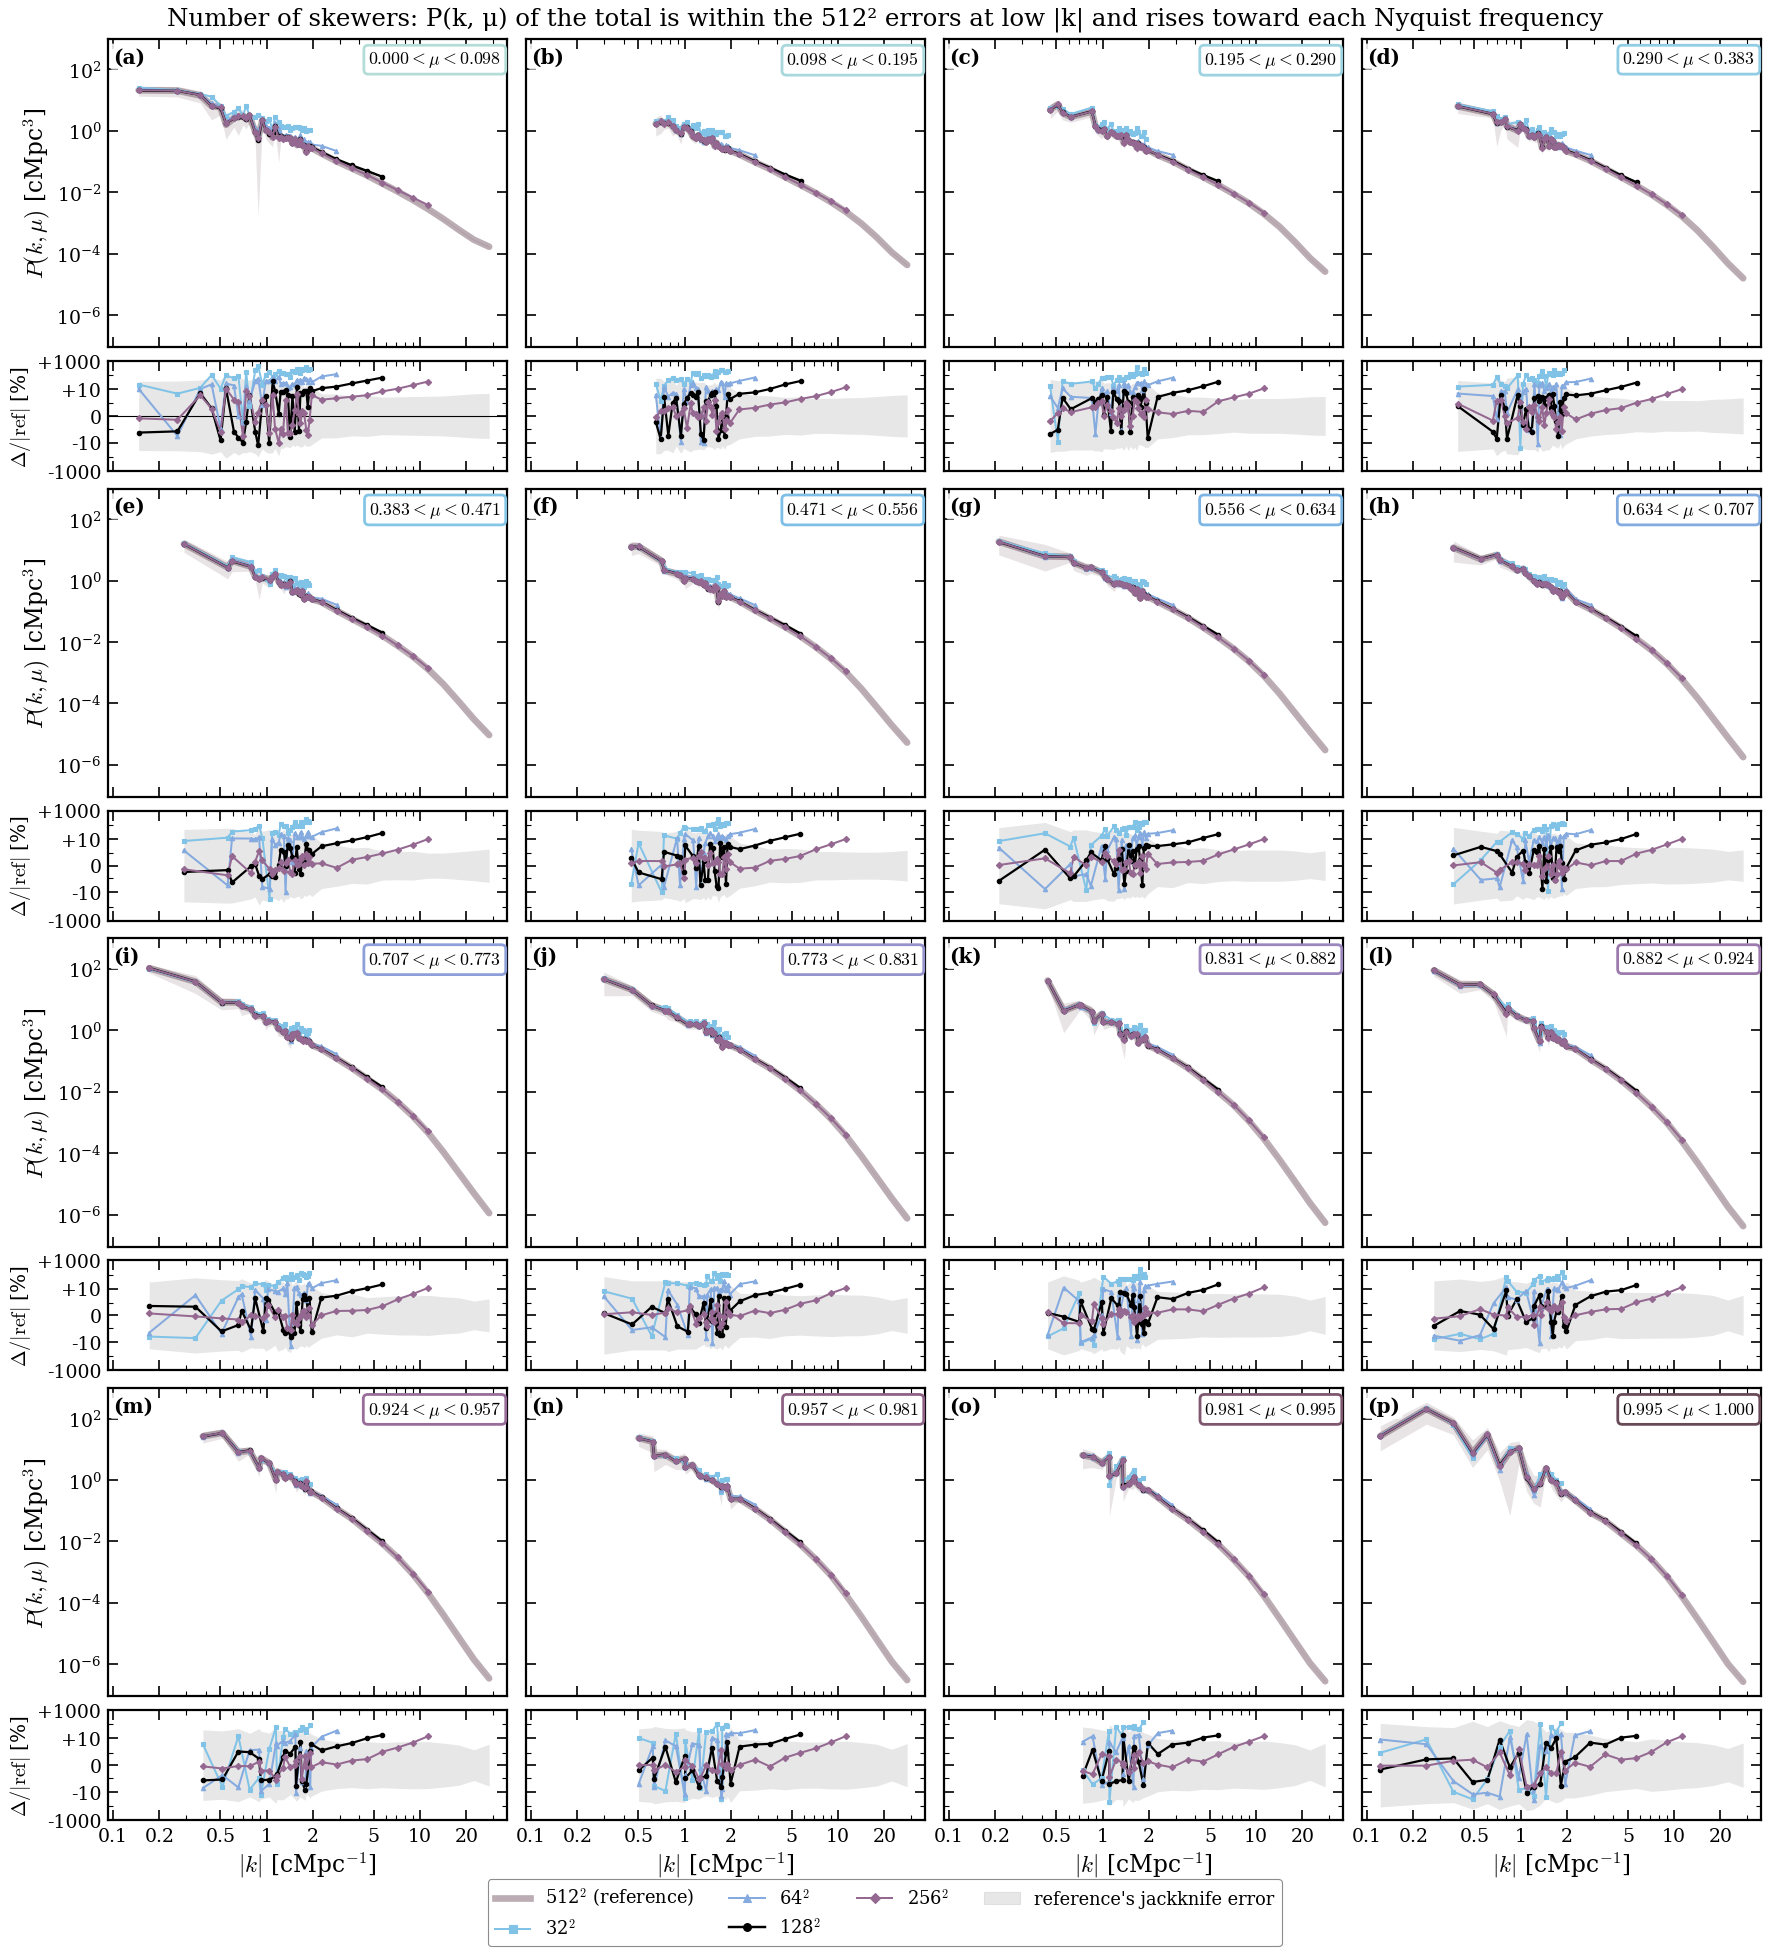

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         total                                  50.2          462        30.2      61%
n_0064         total                                  9.01          115        28.1      18%
n_0128         total                                  1.97         65.6        26.5      11%
n_0256         total                                 0.479         34.8        24.4       7%


In [7]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('total',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'total': "Number of skewers: P(k, μ) of the total is within the 512² errors at low |k| and rises toward each Nyquist frequency"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('total',), "P_mu"))

*Reading (total).* Each lattice stops at its own Nyquist frequency $\pi N/L$ (masked beyond). At low $|k|$ every
lattice is inside the 25–30% jackknife error of $512^2$; toward its Nyquist frequency each rises above it, in every wedge,
by transverse aliasing. Median $|\Delta|$: 50, 9.0, 2.0 and 0.48% at $32^2$ … $256^2$.

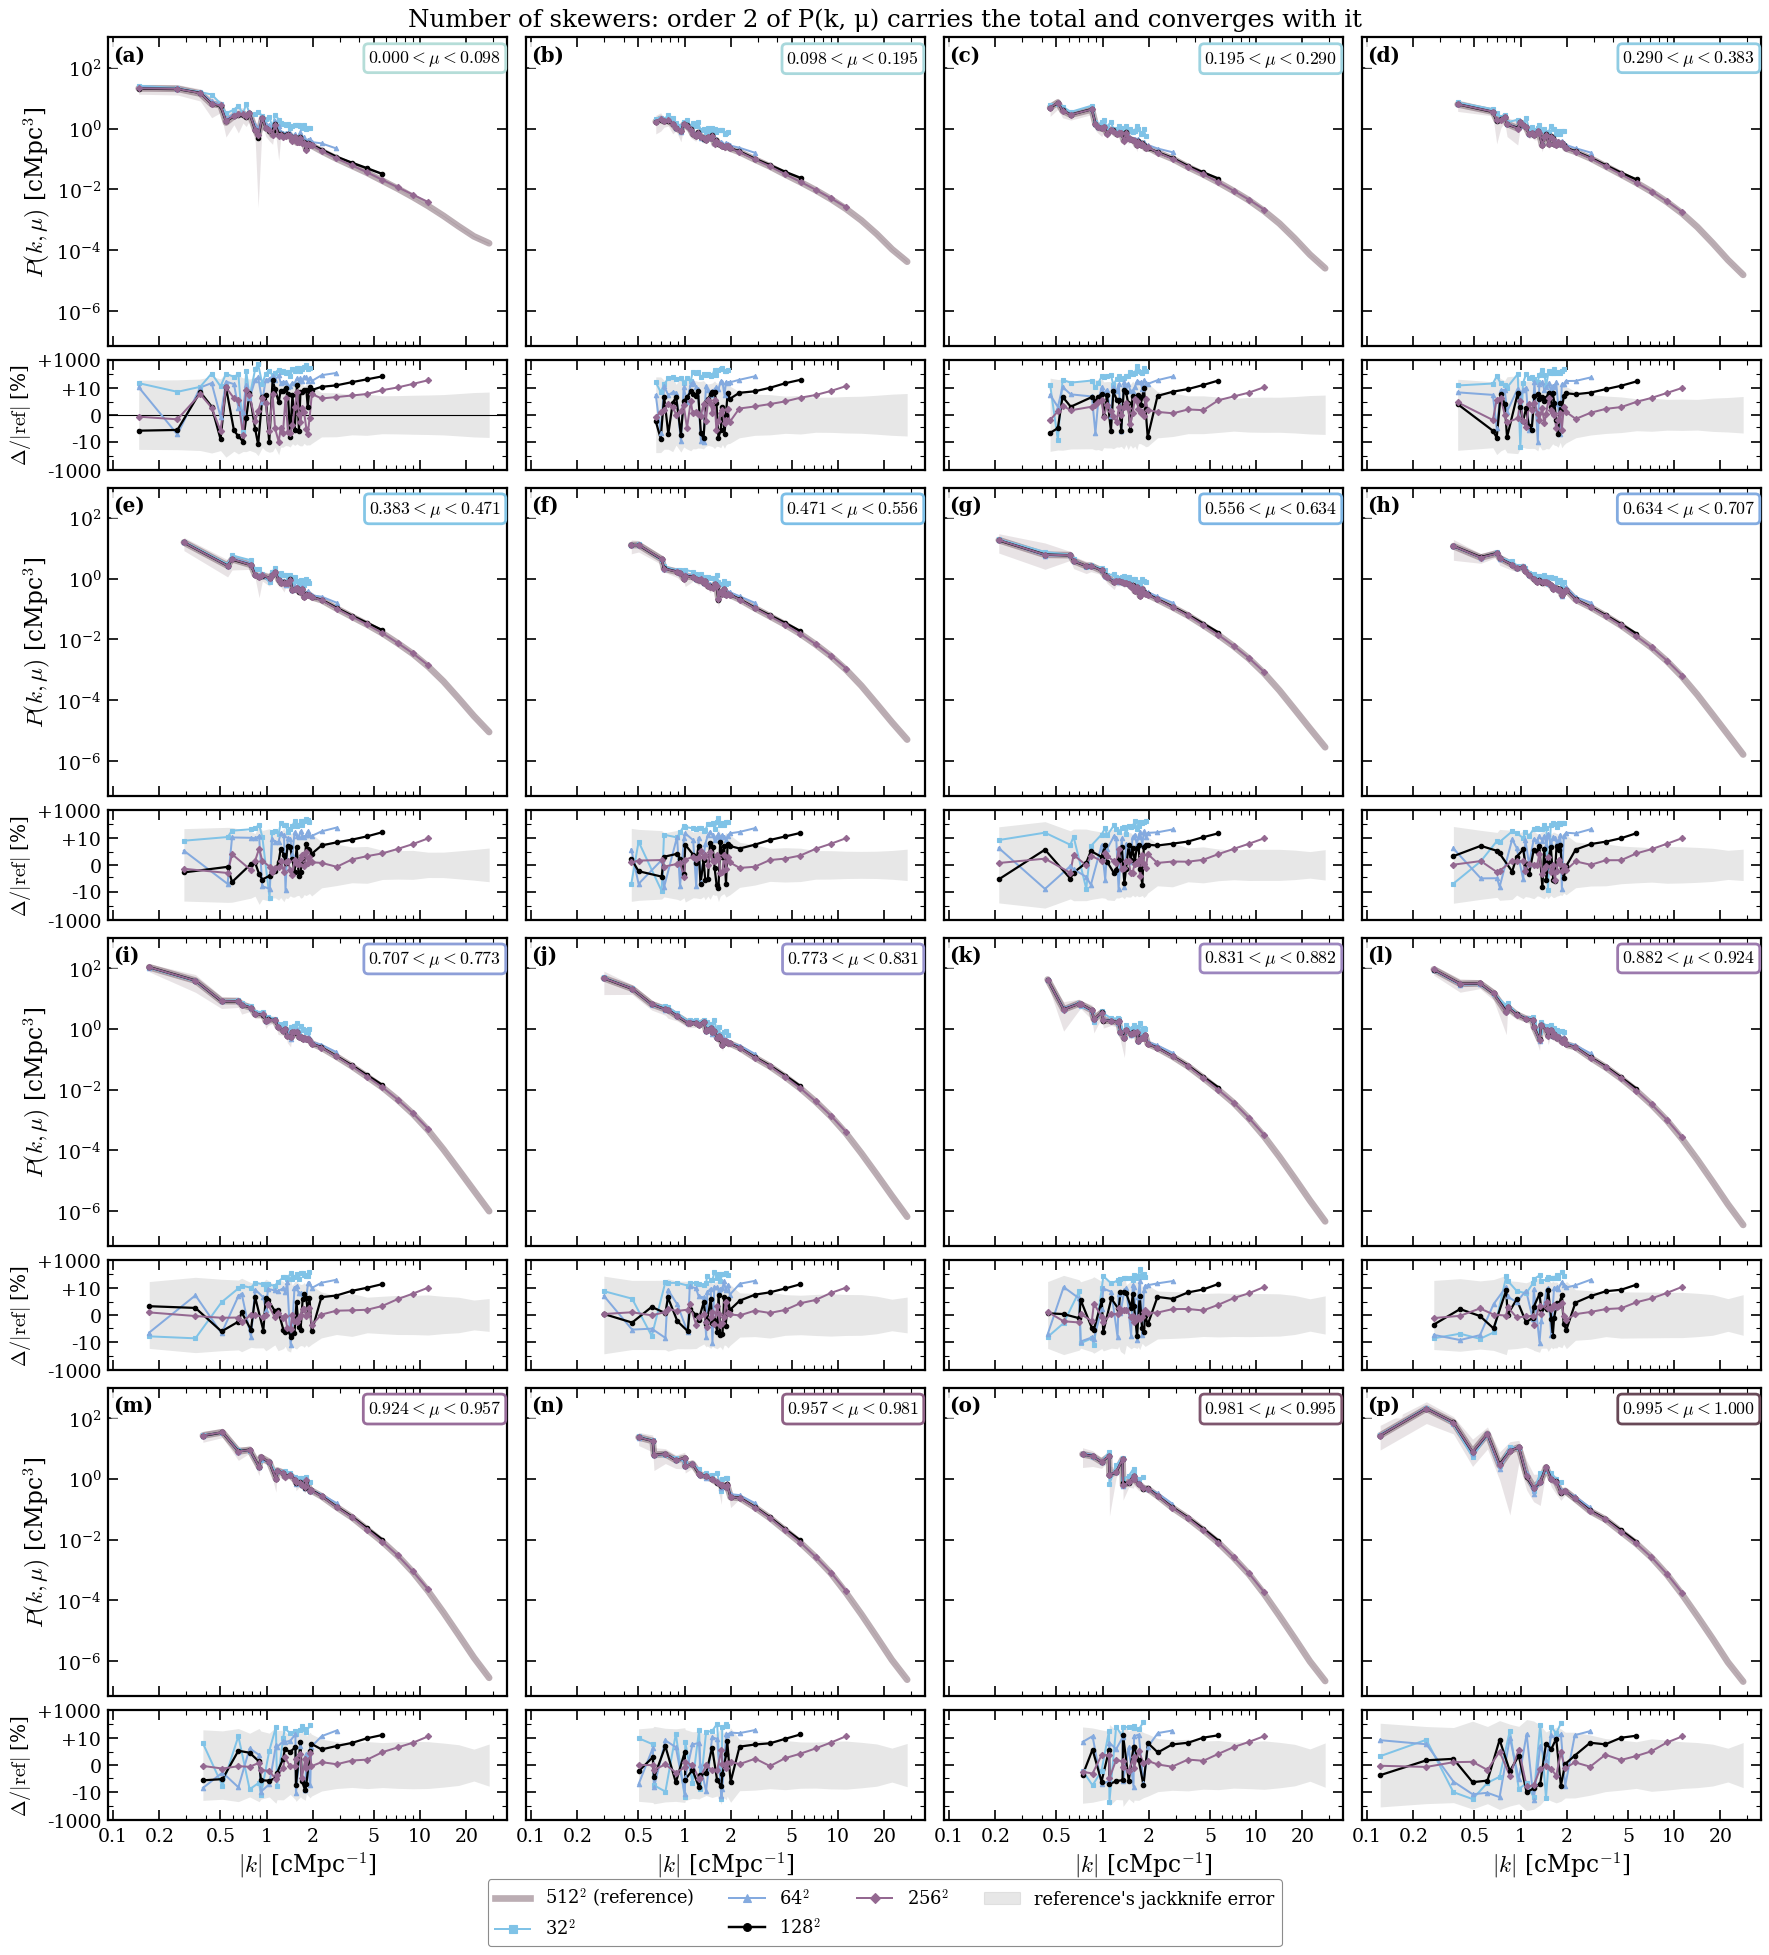

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         order 2                                49.9          465        30.3      61%
n_0064         order 2                                   9          115        28.1      18%
n_0128         order 2                                1.87         66.1        26.5      10%
n_0256         order 2                               0.479           35        24.4       7%


In [8]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 2',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 2': "Number of skewers: order 2 of P(k, μ) carries the total and converges with it"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 2',), "P_mu"))

*Reading (order 2).* Order 2 is the total to a part in $10^3$: the same medians, 50, 9.0, 1.9 and 0.48%.

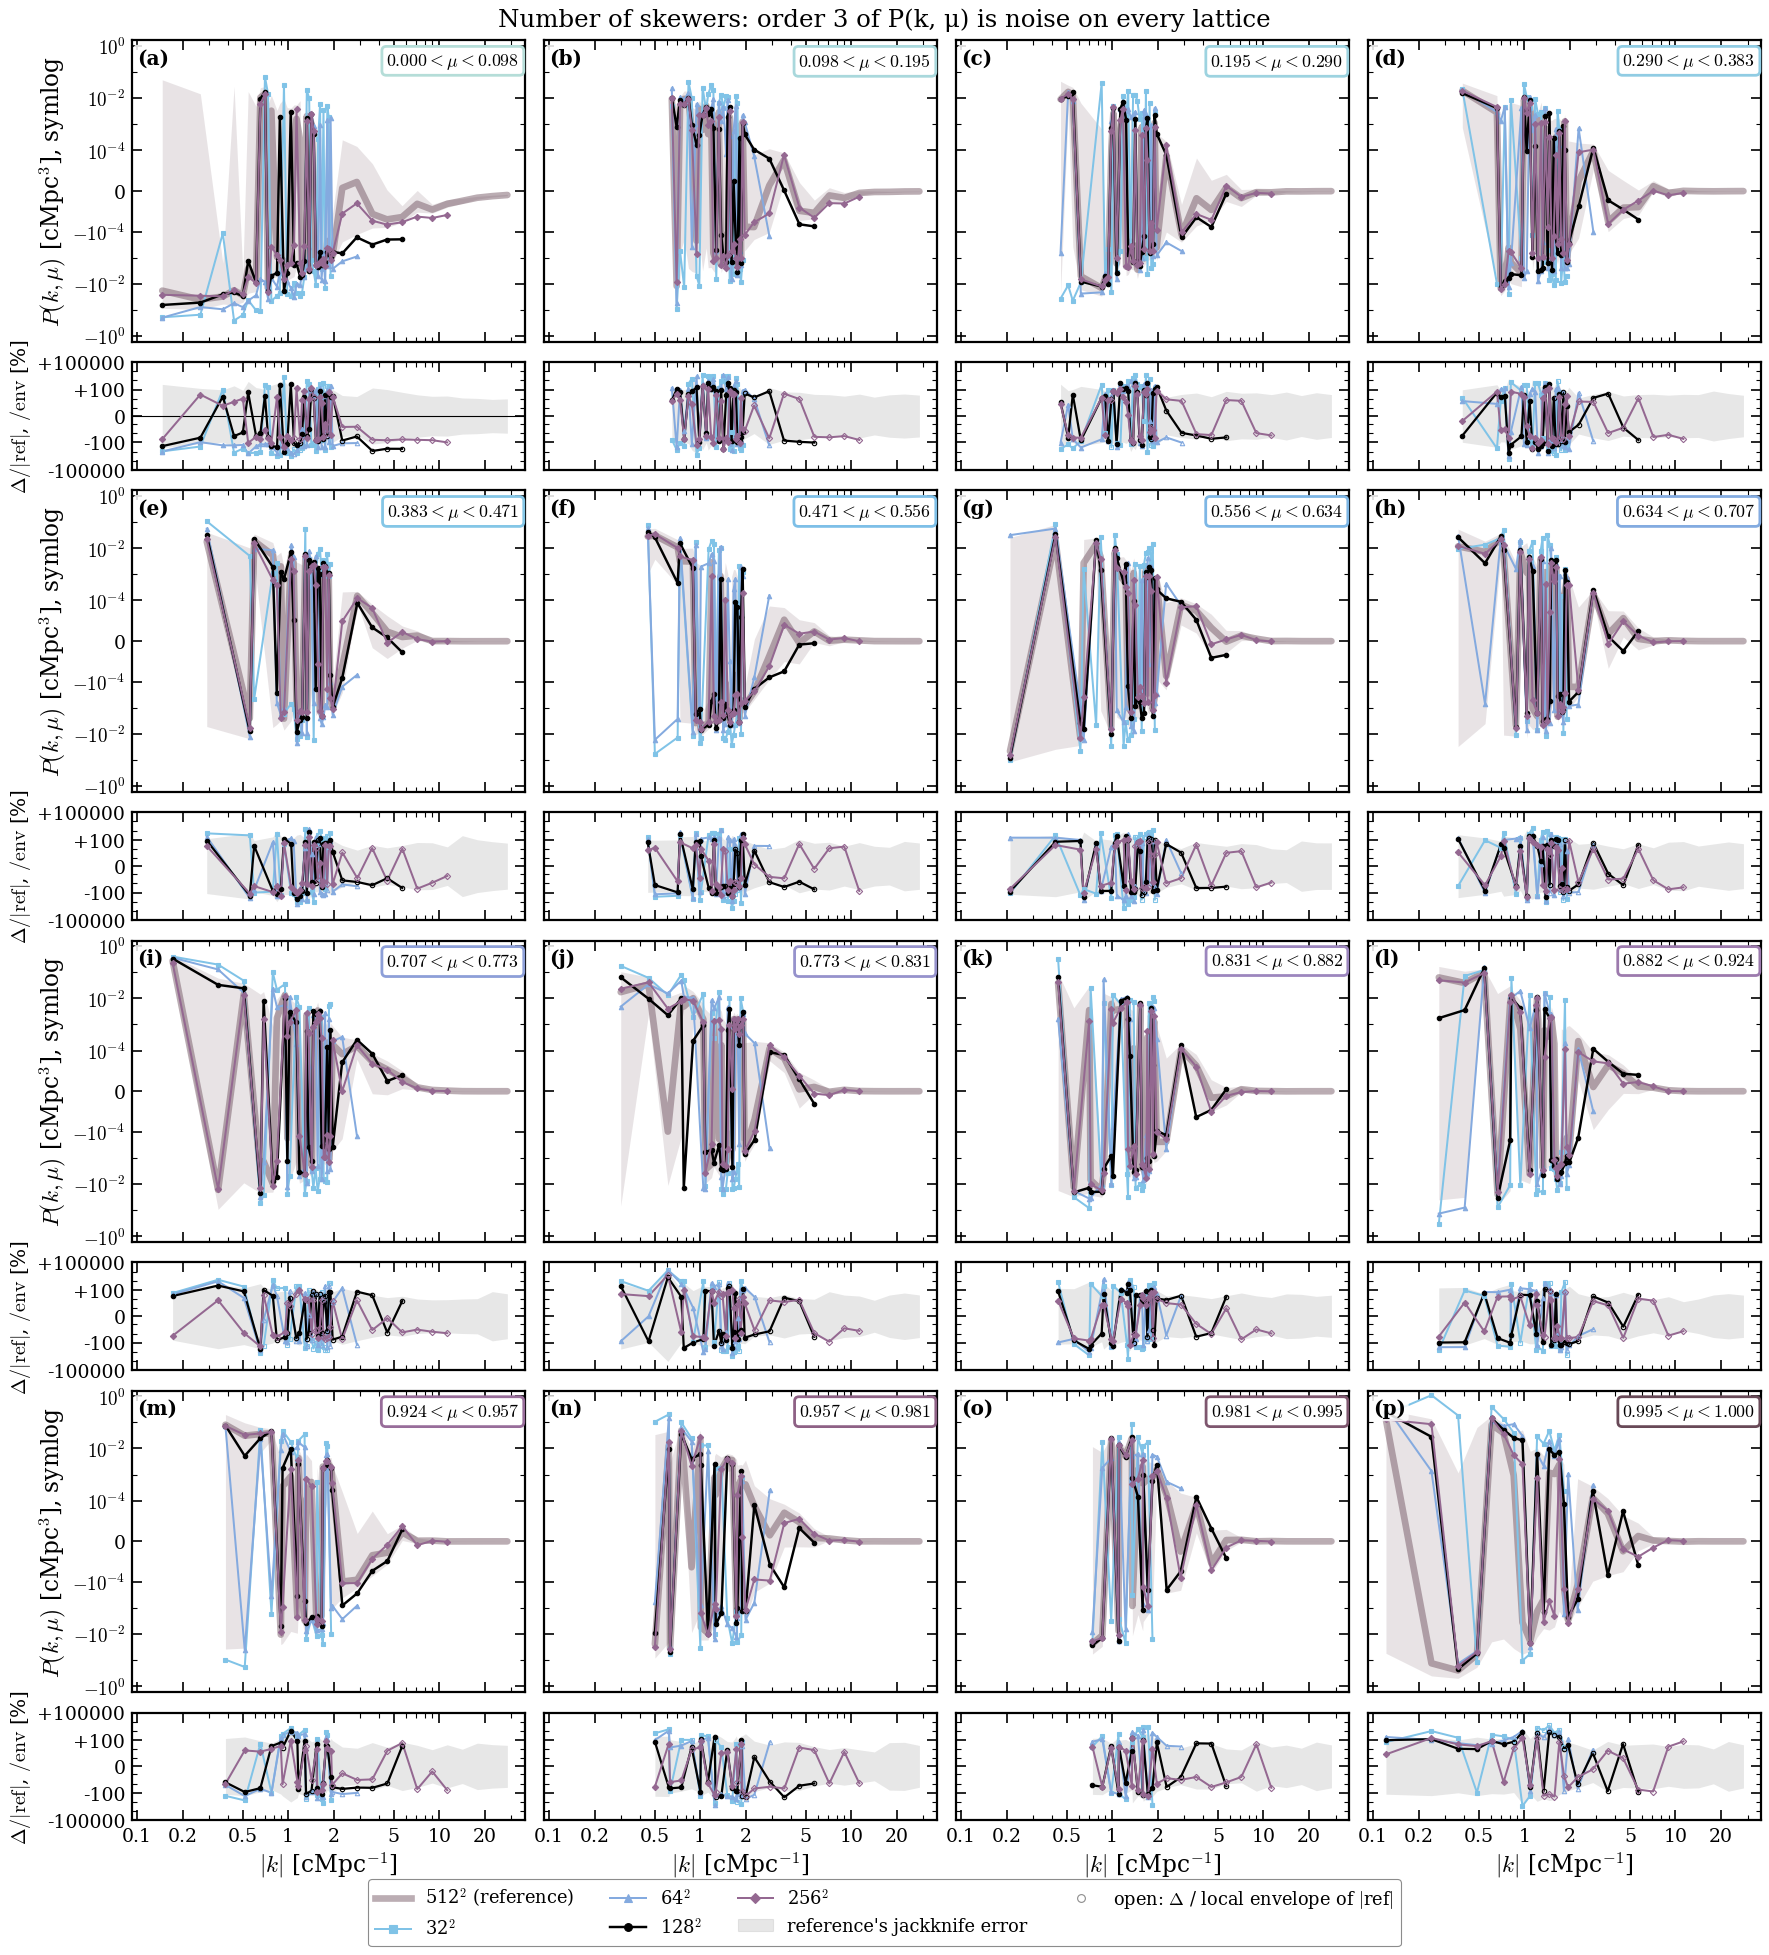

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         order 3                                 359     1.36e+04         135      78%
n_0064         order 3                                 136     1.58e+04         127      51%
n_0128         order 3                                46.4     2.41e+03         109      17%
n_0256         order 3                                18.7     4.22e+03         102       4%


In [9]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 3',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 3': "Number of skewers: order 3 of P(k, μ) is noise on every lattice"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 3',), "P_mu"))

*Reading (order 3).* Order 3 changes sign from bin to bin, with errors above 100% of its envelope; the coarse
lattices depart further (median 360% at $32^2$, 19% at $256^2$), mostly near their Nyquist frequency.

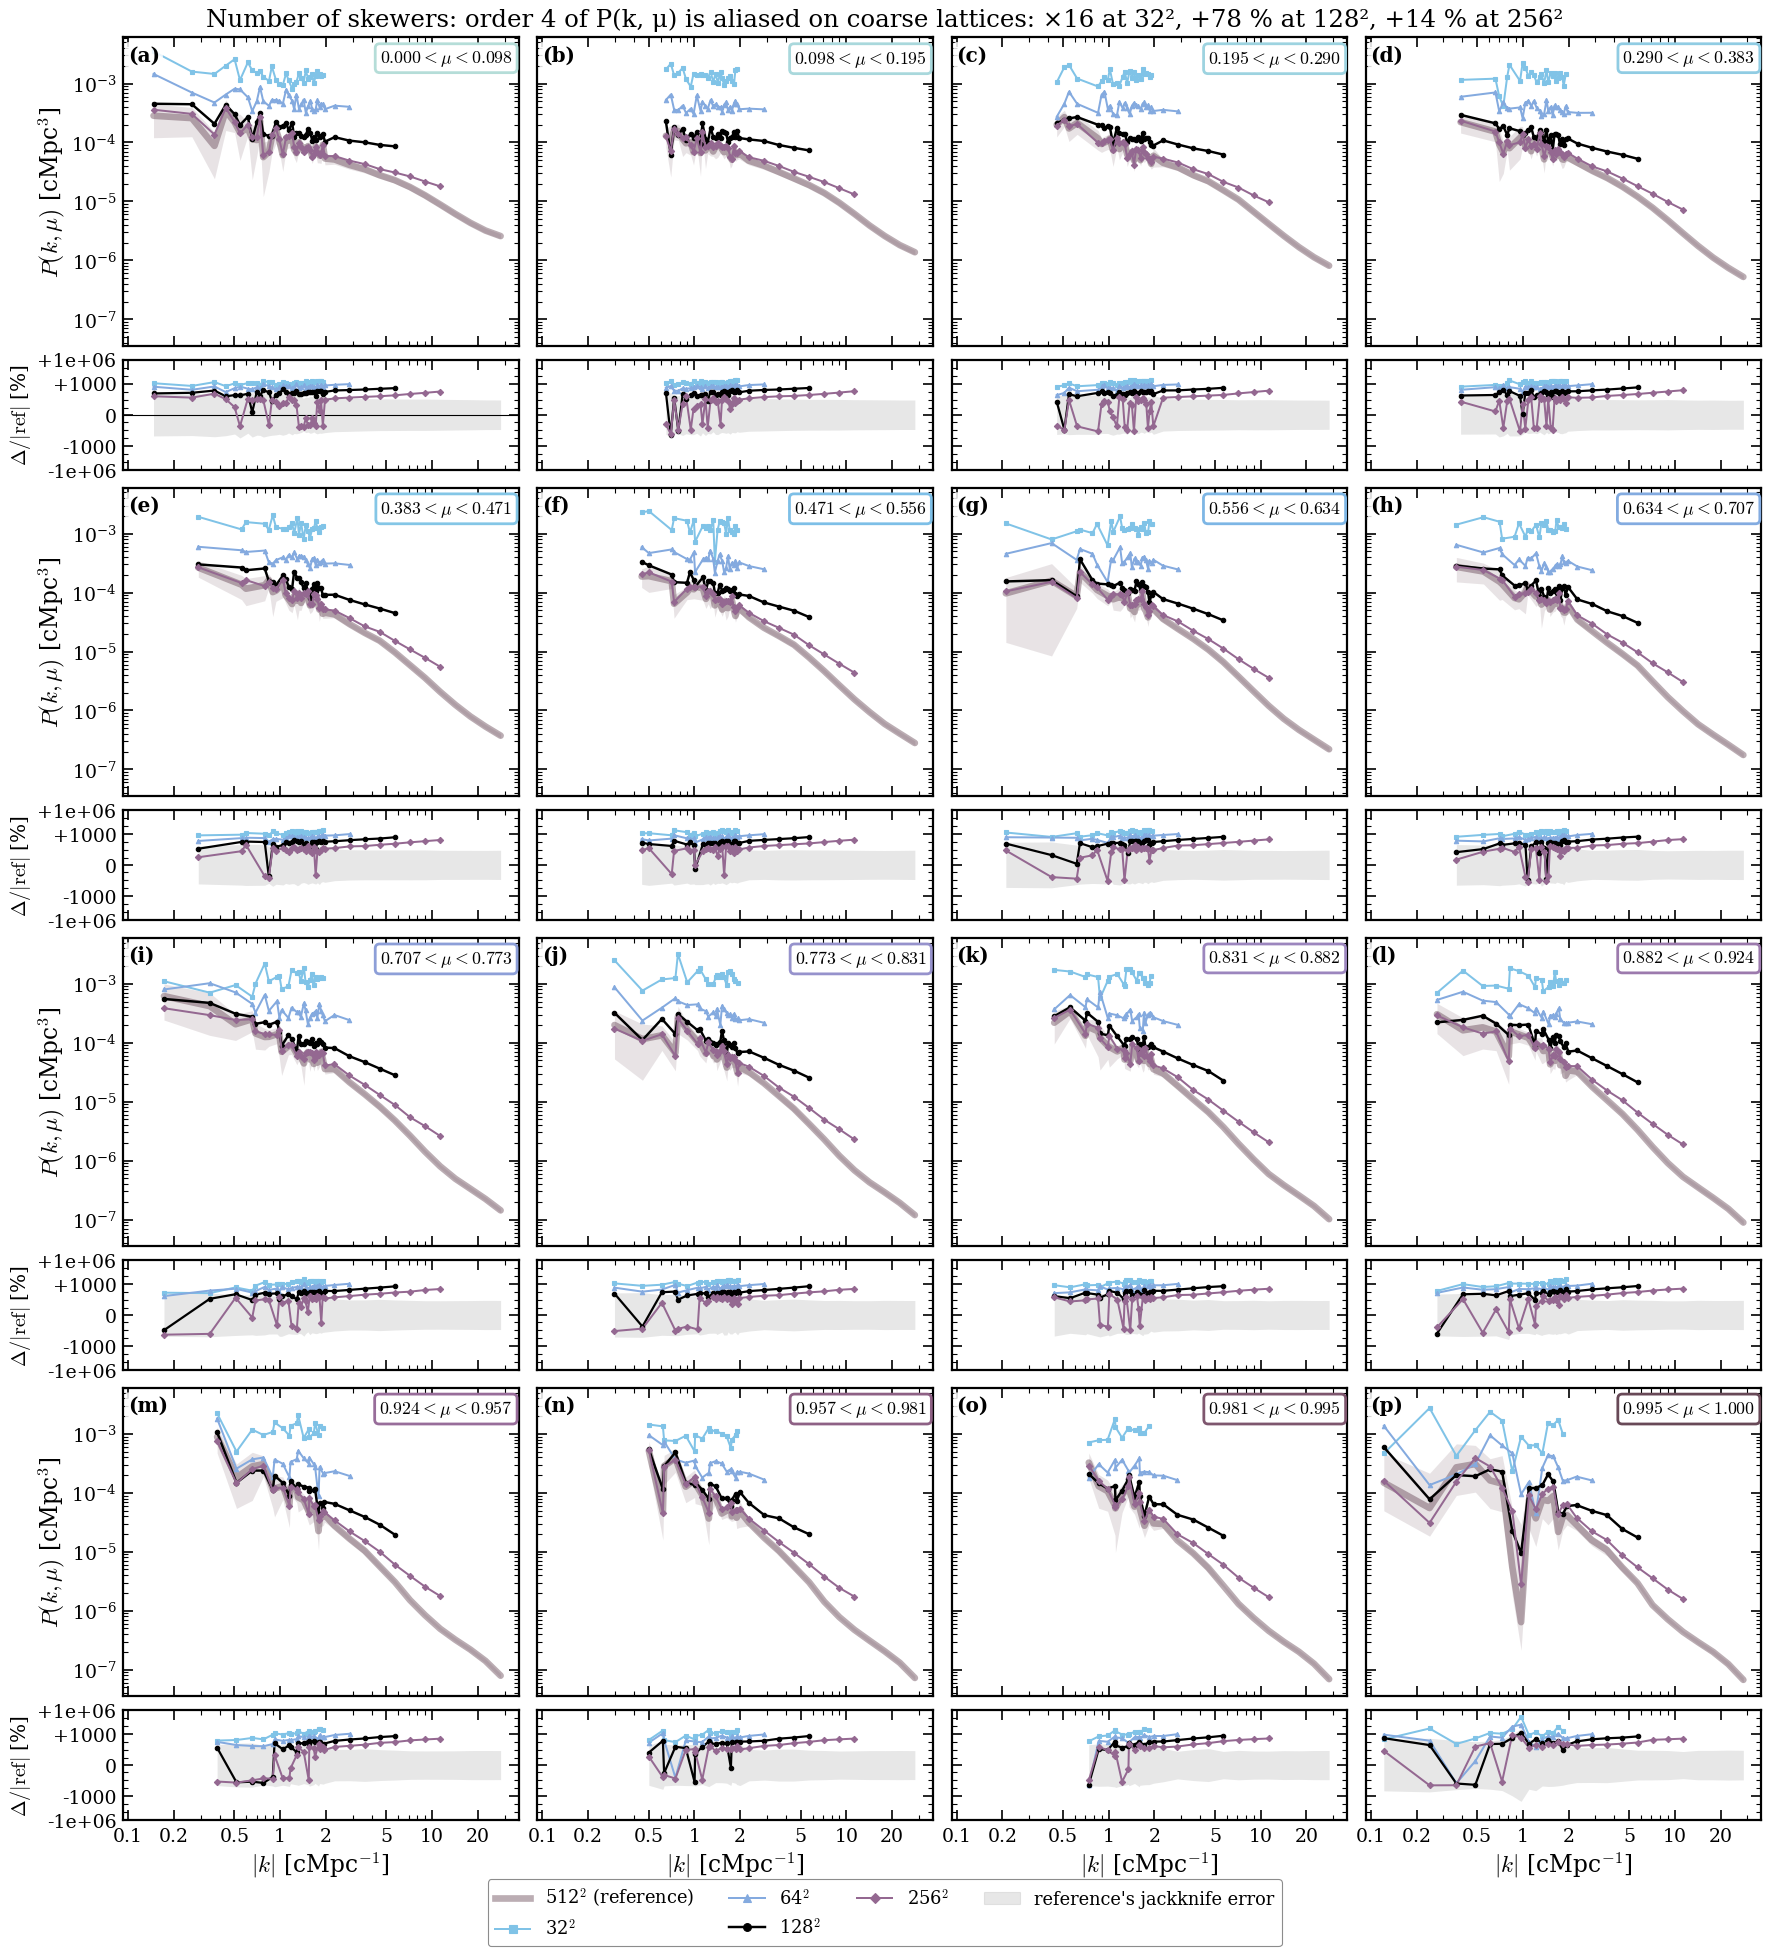

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         order 4                            1.48e+03      1.4e+05        31.3      99%
n_0064         order 4                                 388     1.47e+04        29.9      97%
n_0128         order 4                                77.6     1.39e+03        28.1      78%
n_0256         order 4                                  14          808        26.9      30%


In [10]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 4',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 4': "Number of skewers: order 4 of P(k, μ) is aliased on coarse lattices: ×16 at 32², +78 % at 128², +14 % at 256²"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 4',), "P_mu"))

*Reading (order 4).* The coarser lattices lie above $512^2$ at every $|k|$ and in every wedge, not only near
their Nyquist frequency: median +1500, +390, +78 and +14% at $32^2$ … $256^2$. Order 4 is the power of
$\delta_{\rm Ly\alpha}\delta_{\rm Si\,III}$, a field of small dense absorbers with power far beyond the transverse
Nyquist frequency $\pi N/L$ of a coarse lattice, which folds back into every bin. The total, dominated by the
$\mathrm{Ly}\alpha$ auto, hides it.

### E2 · The wedges term by term (order 2)

One figure each for the $\mathrm{Ly}\alpha$ auto, the Si III auto and the cross term.

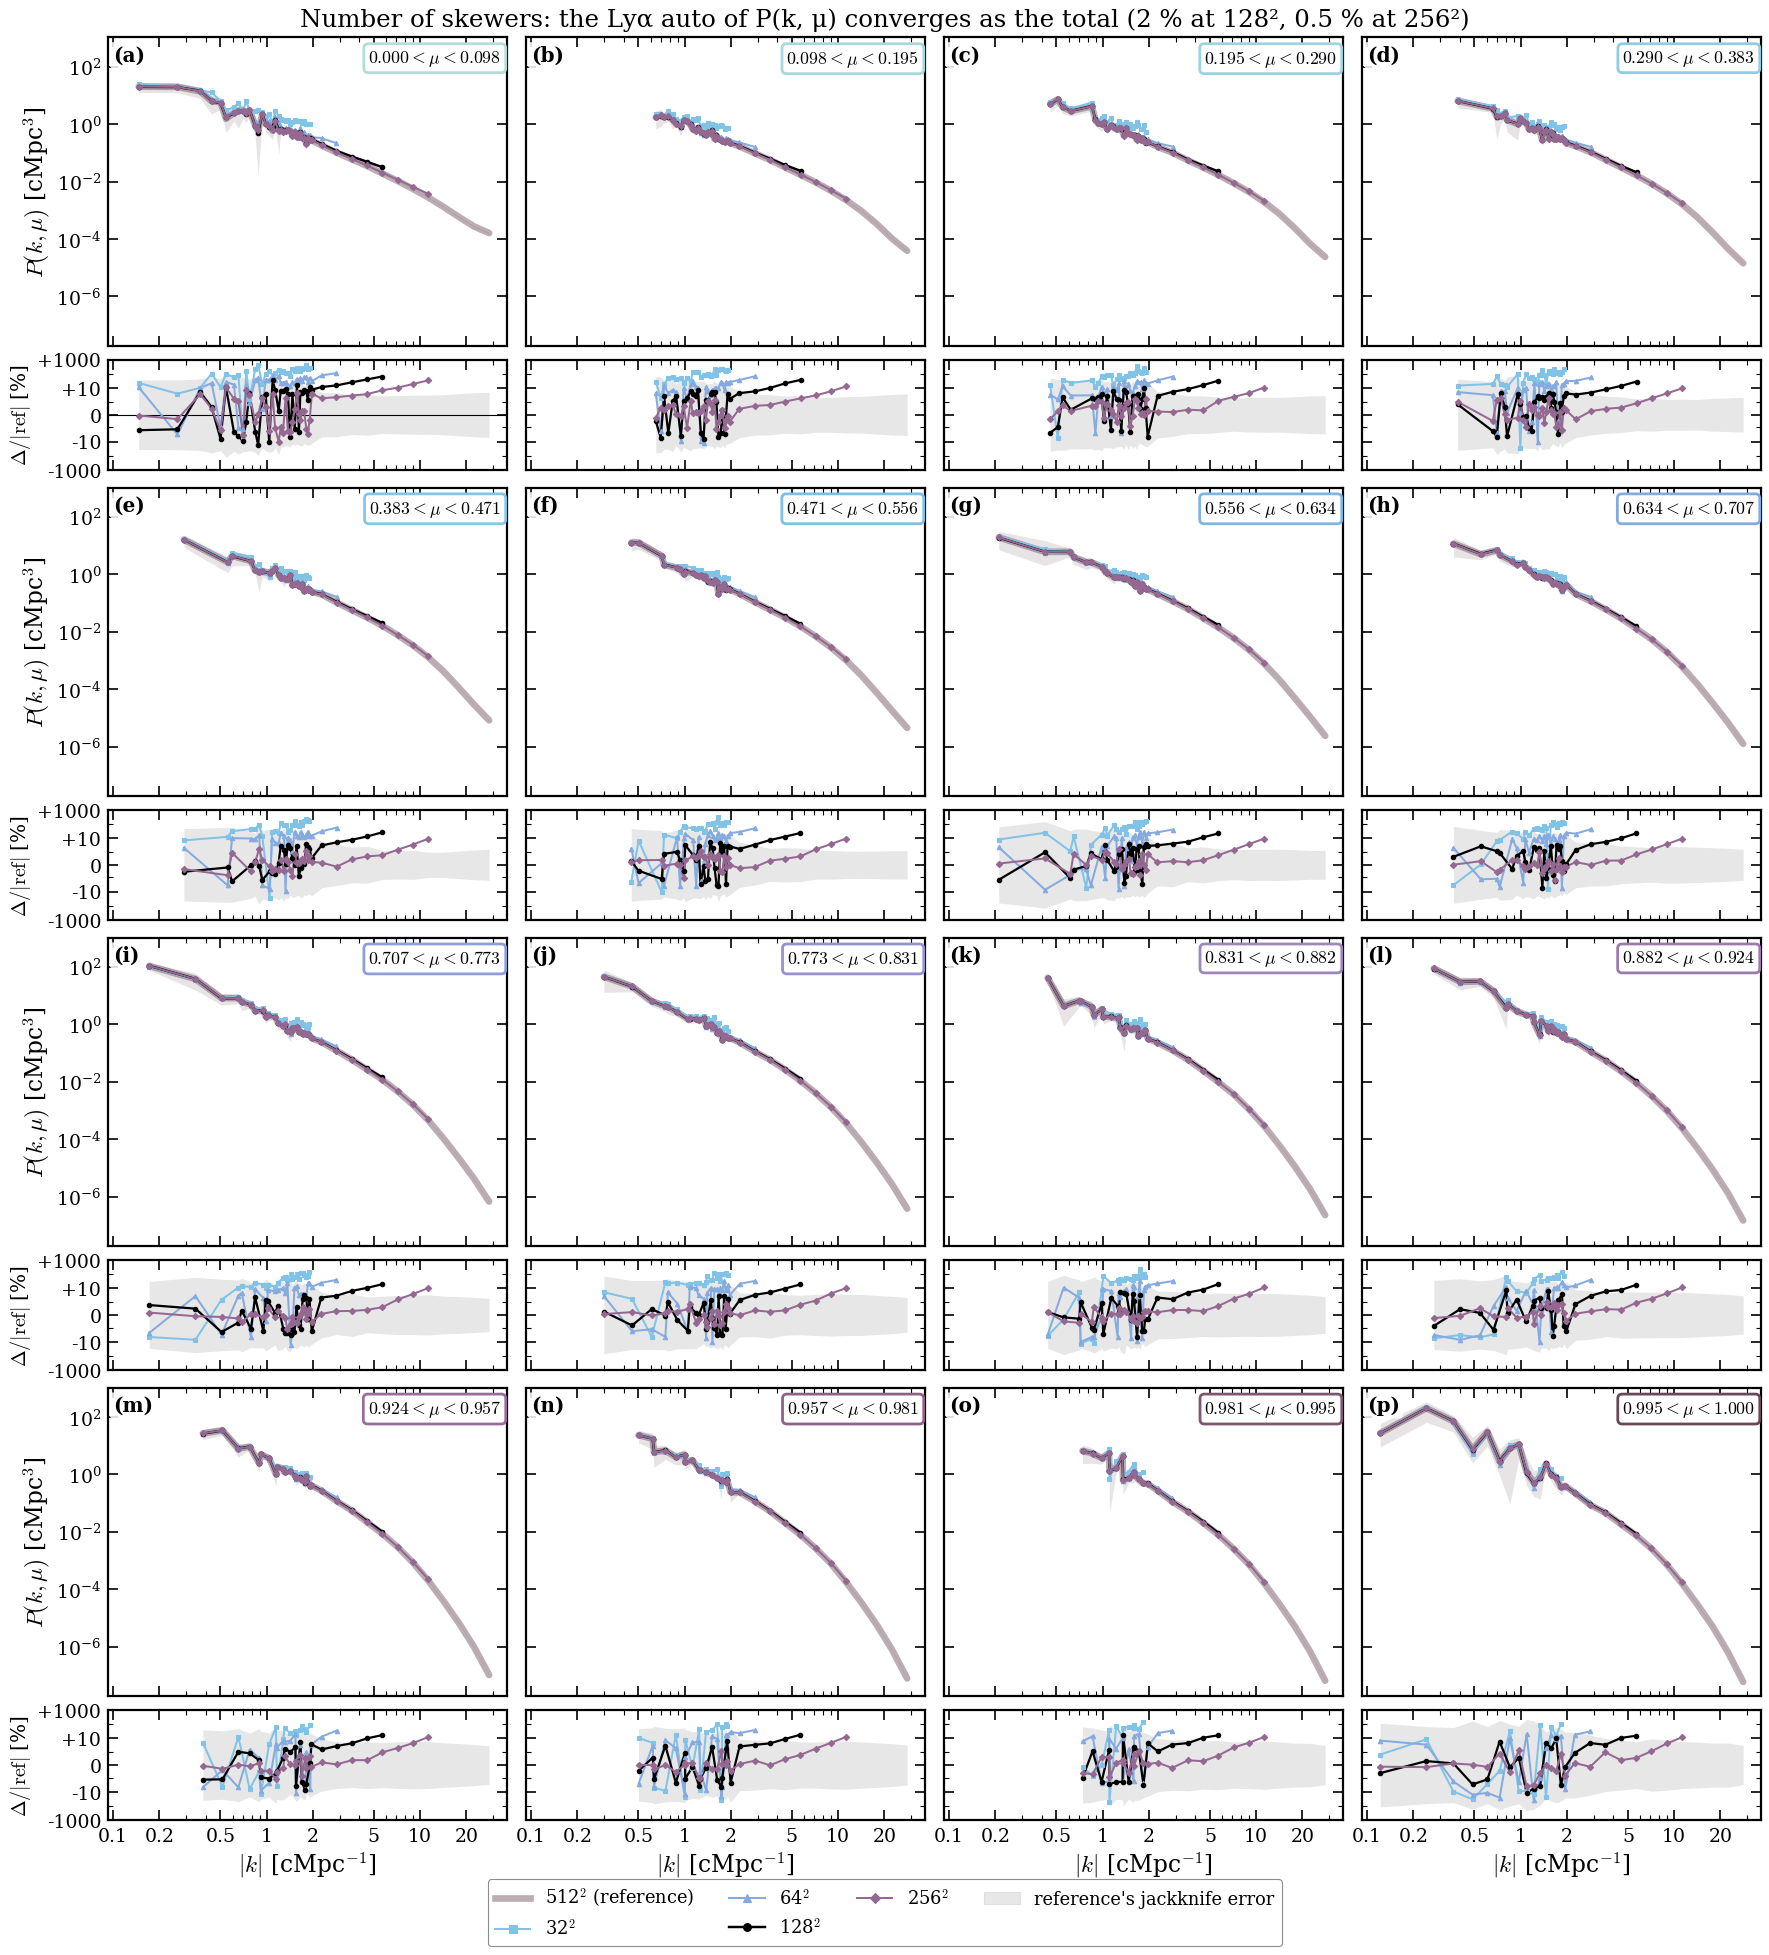

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         HI-LyA|HI-LyA                          49.9          426        30.2      61%
n_0064         HI-LyA|HI-LyA                          8.93          113        28.3      17%
n_0128         HI-LyA|HI-LyA                          1.95         64.6        26.6      10%
n_0256         HI-LyA|HI-LyA                         0.461         34.2        24.4       7%


In [11]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[0],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[0]: "Number of skewers: the Lyα auto of P(k, μ) converges as the total (2 % at 128², 0.5 % at 256²)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[0],), "P_mu"))

*Reading (term 1).* Median 50, 8.9, 2.0 and 0.46% at $32^2$ … $256^2$, the departure concentrated near each Nyquist
frequency, as the total.

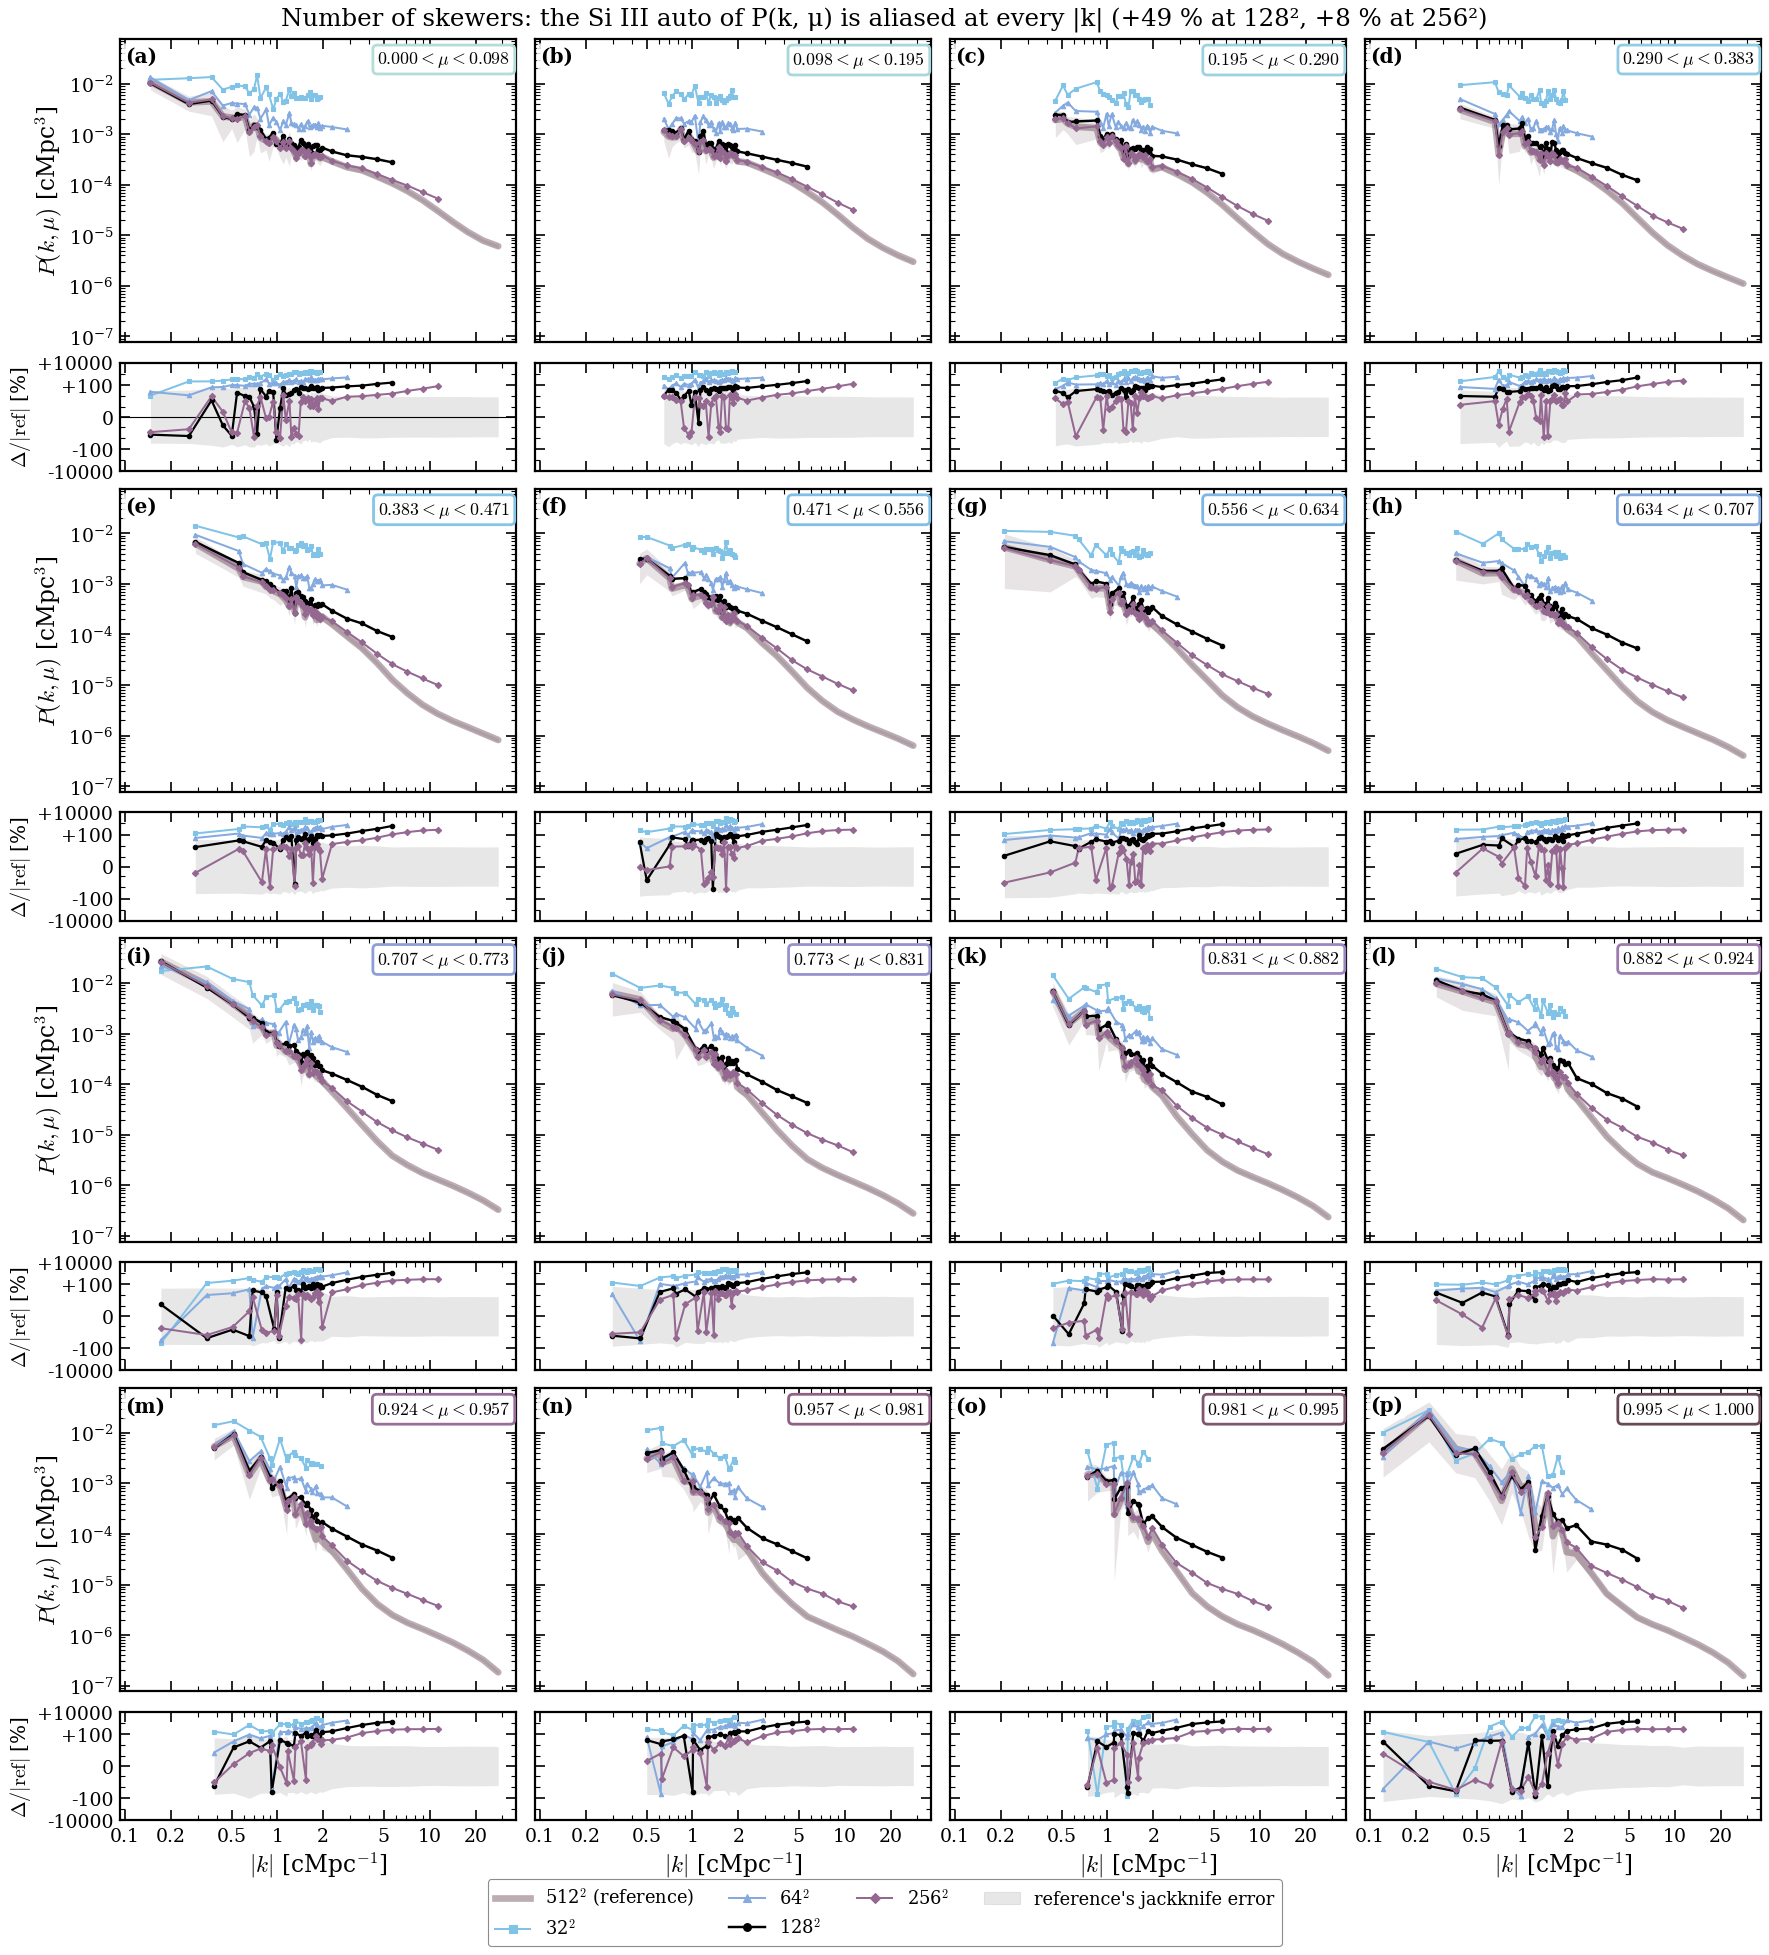

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         SiIII-1206|SiIII-1206              1.03e+03      4.3e+03        30.9      98%
n_0064         SiIII-1206|SiIII-1206                   246        2e+03        29.5      89%
n_0128         SiIII-1206|SiIII-1206                  48.5     1.36e+03        27.9      65%
n_0256         SiIII-1206|SiIII-1206                  7.74          299        26.3      25%


In [12]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[1],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[1]: "Number of skewers: the Si III auto of P(k, μ) is aliased at every |k| (+49 % at 128², +8 % at 256²)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[1],), "P_mu"))

*Reading (term 2).* As order 4: every coarser lattice lies above $512^2$ at every $|k|$, by a median $\times 11$ ($32^2$),
$\times 3.5$ ($64^2$), +49% ($128^2$) and +8% ($256^2$). Si III absorbs in small dense systems whose power extends beyond the
transverse Nyquist frequency and folds back. A 3D Si III measurement needs $256^2$ skewers or more here.

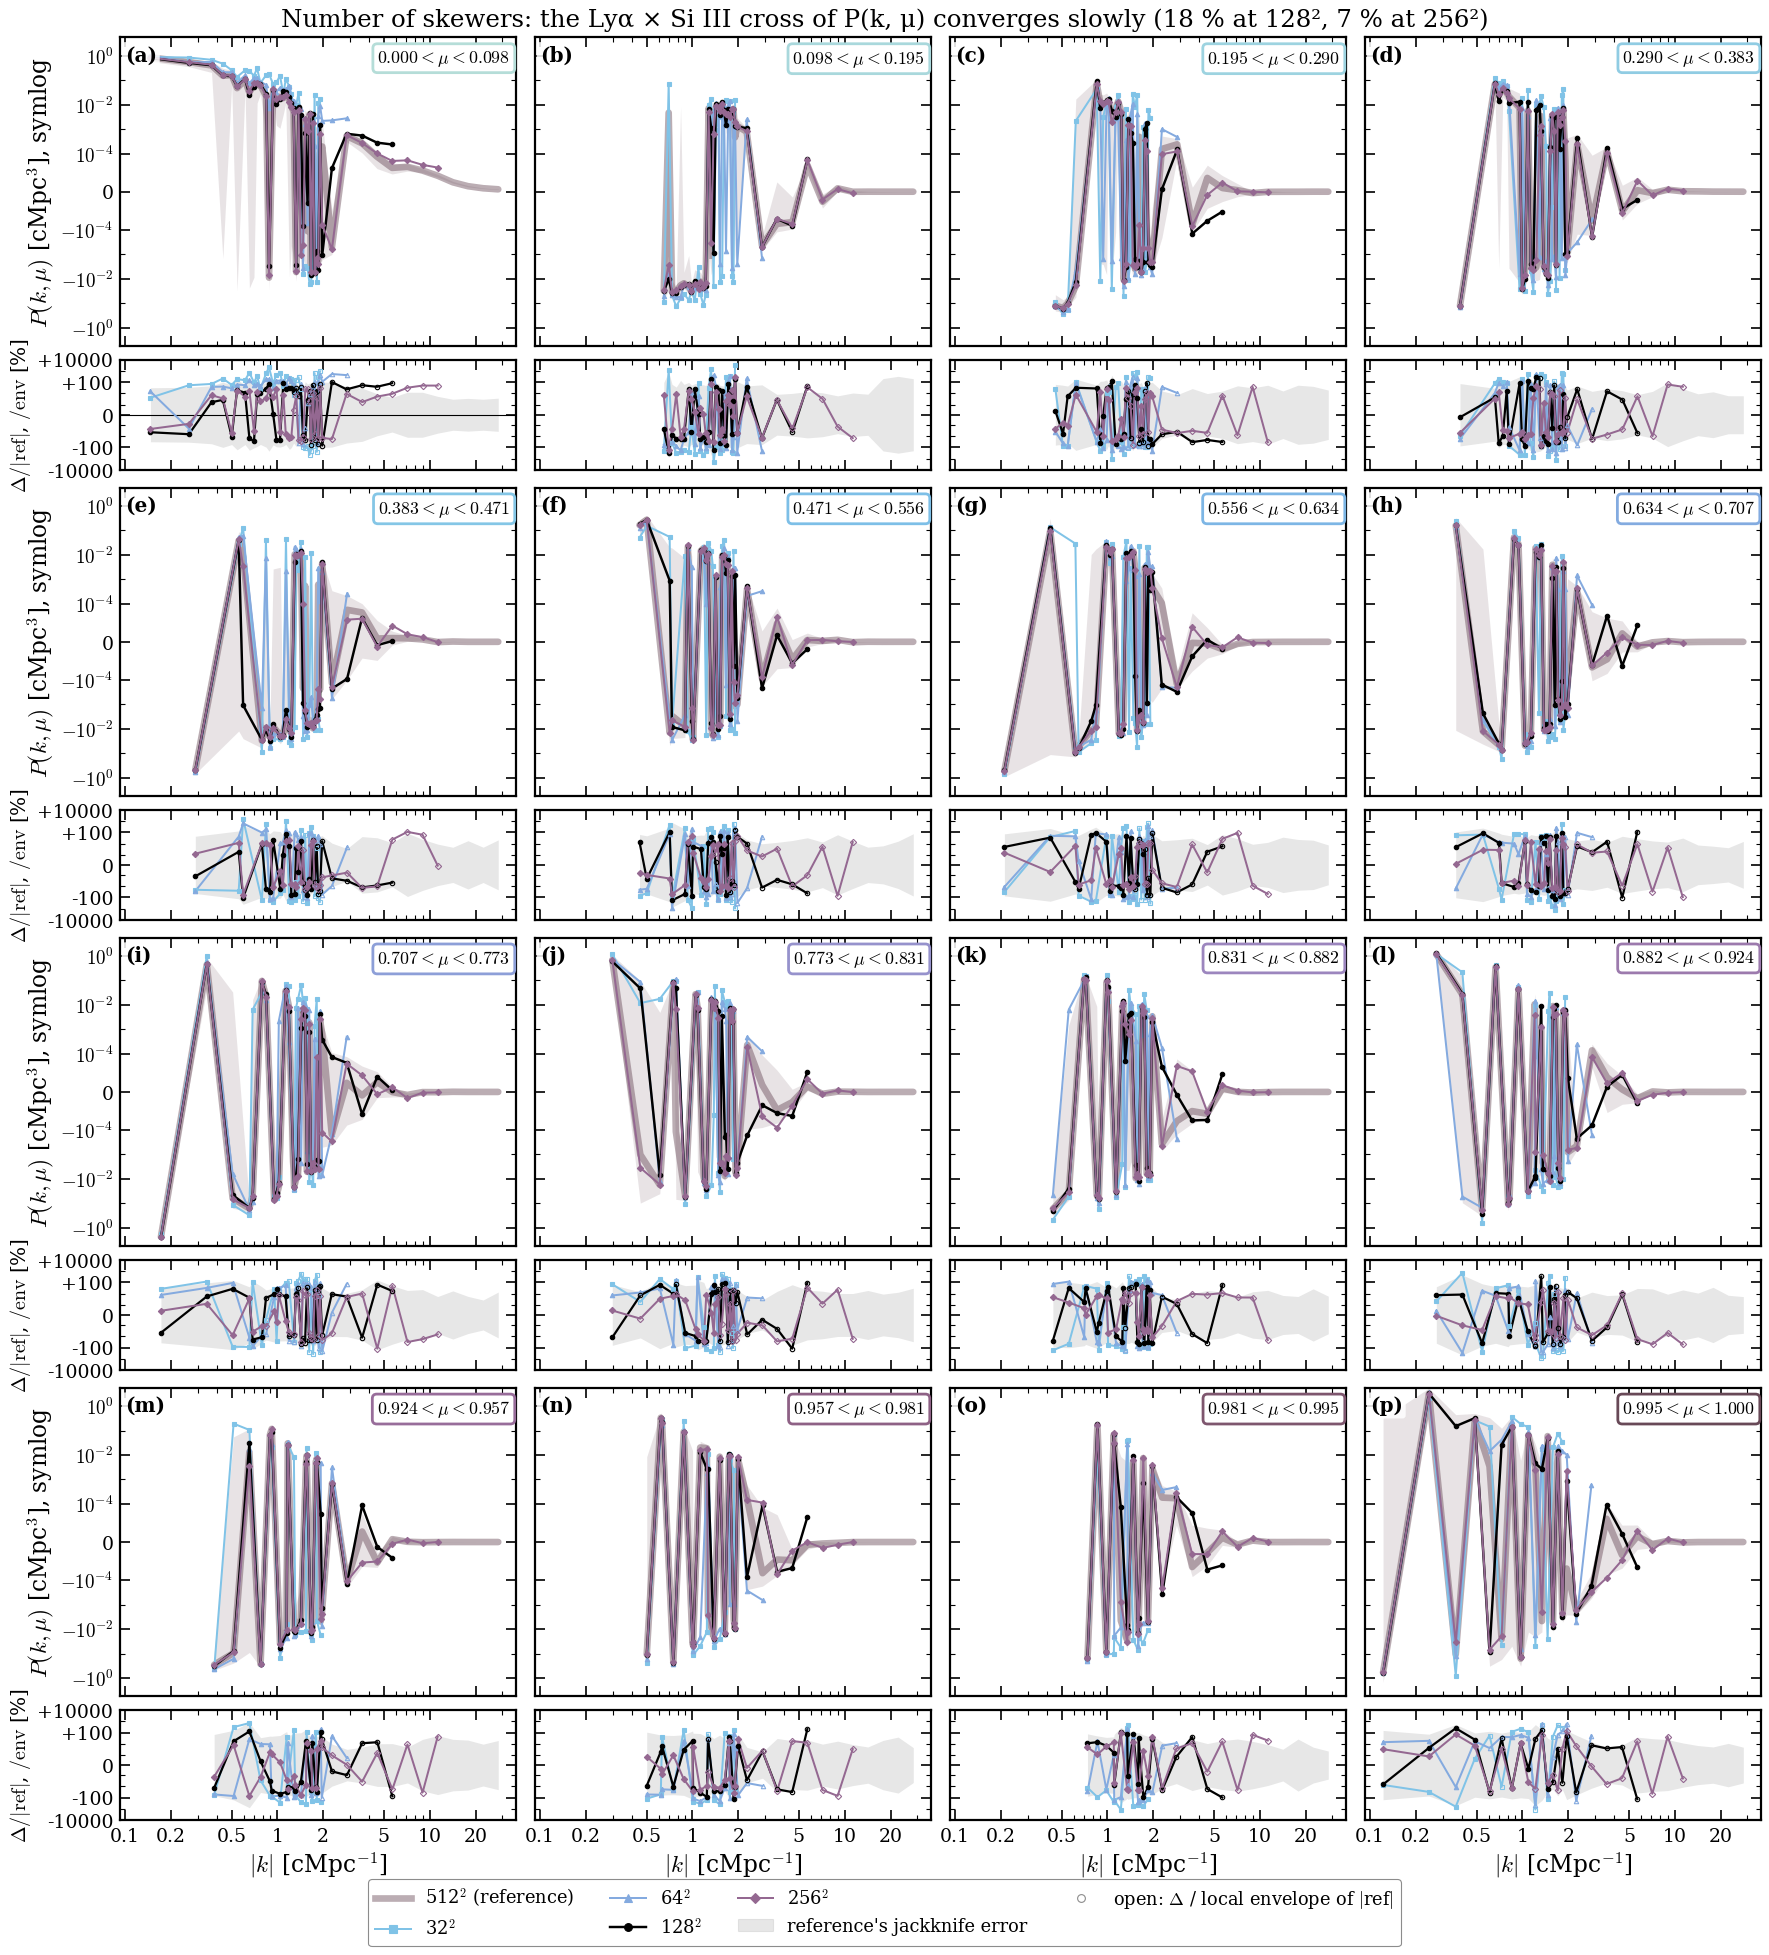

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
n_0032         HI-LyA|SiIII-1206                       132     3.23e+03        64.7      69%
n_0064         HI-LyA|SiIII-1206                      51.2          880          61      41%
n_0128         HI-LyA|SiIII-1206                      17.7          341          56      13%
n_0256         HI-LyA|SiIII-1206                      6.99          307          53       8%


In [13]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[2],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[2]: "Number of skewers: the Lyα × Si III cross of P(k, μ) converges slowly (18 % at 128², 7 % at 256²)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[2],), "P_mu"))

*Reading (term 3).* Relative to its local envelope the cross differs by a median 130, 51, 18 and 7% at $32^2$ …
$256^2$, inside its large error (55–65%) from $128^2$ on.

## Part F — The converged range

For every run and statistic, the largest $k$ up to which **every** bin differs from the reference by less than 0.1%,
0.5% and 1% (`k_max_table`: P1D on its native modes, $P(k, \mu)$ on its $|k|$ bins; "$\geq k$" when every bin passes up to
the run's last one; 0 when the first bin already fails). The last columns give the run's last bin and the median
jackknife error of the relative difference: a $k_{\max}$ set by bins whose difference is within that error is limited
by noise, not by the parameter. The figure draws $k_{\max}(0.5\%)$ against the number of skewers.

against n_0512; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes up to the run's last one; the DESI DR1 P1D reaches k = 0.032 s/km at z = 3.0
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
n_0032         P1D HI-LyA                            0.00159        0.00159        0.00318      3.14       0.12  s/km
n_0032         P1D SiIII-1206                              0              0              0      3.14         14  s/km
n_0032         P1D total                                   0        0.00159        0.00318      3.14         14  s/km
n_0032         P(k, mu) total mu 0.00-0.50                 0              0              0      1.91         21  1/cMpc
n_0032         P(k, mu) total mu 0.50-0.80                 0              0              0      1.91         16  1/cMpc
n_0032         P(k, mu) total mu 0.80-0.95                 0              0              0      1.91   

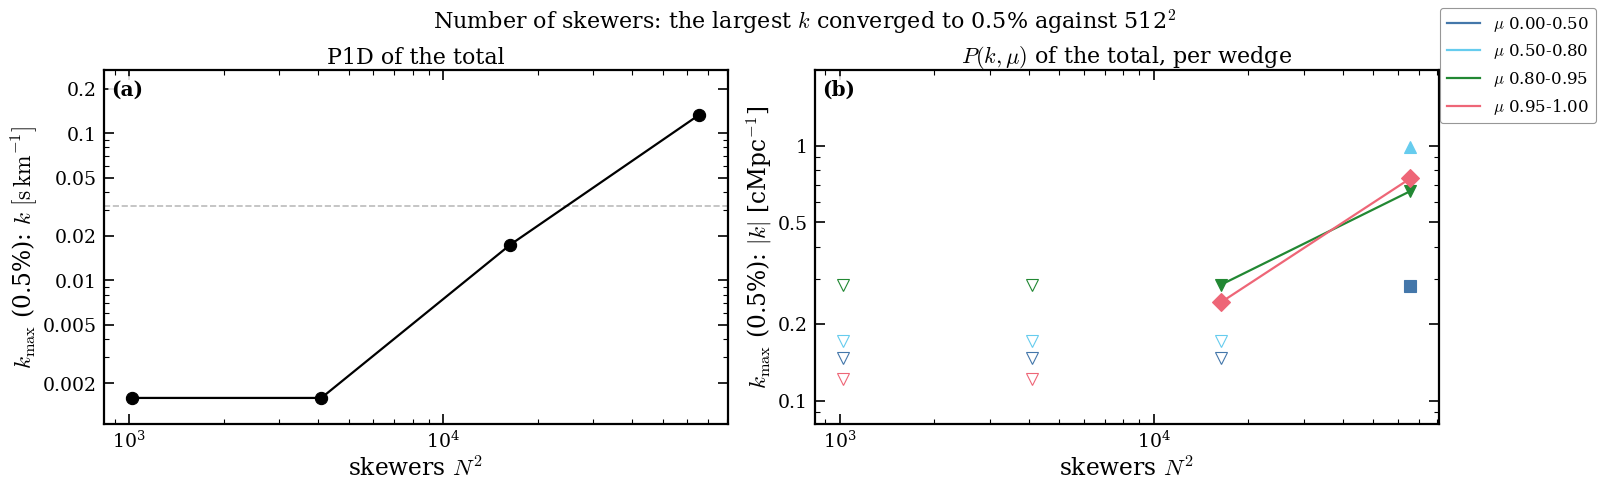

In [14]:
ROWS = k_max_table(CMP_ALL, TOLS)
print(f"against {REFERENCE}; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes "
      f"up to the run's last one; the DESI DR1 P1D reaches k = {K_DESI:.3f} s/km at z = {P1D_REF['z']}")
print(format_k_max_table(ROWS, TOLS))
fig, axs = plot_k_max_summary(ROWS, X_OF_RUN, xlabel=X_LABEL, xscale=X_SCALE, xticks=X_TICKS, tol=0.005, p1d_k_ref=K_DESI,
                              title=f"{TITLE_STEM}: the largest $k$ converged to 0.5% against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()

**Reading.** The sub-lattices are subsets of the $512^2$ skewers. Their differences from it are sample variance,
correlated with the reference, plus aliasing of the transverse modes near each lattice's own Nyquist frequency
$\pi N/L$: the excess of $P(k, \mu)$ at the high-$|k|$ end of every lattice.

* **Mean transmission:** within $2\sigma$ of $512^2$ for every lattice ($\mathrm{Ly}\alpha$ $+0.32 \pm 0.28$% at $32^2$,
  $+0.044 \pm 0.024$% at $256^2$).
* **$P_\mathrm{1D}$ of the total:** within 0.5% up to $k$ = 0.0175 s/km at $128^2$ and 0.13 s/km at $256^2$. $32^2$ and
  $64^2$ already differ at the first modes, by the sample variance of 1,024 and 4,096 skewers.
* **$P(k, \mu)$:** $128^2$ reaches 0.5% only near the line of sight (to 0.24–0.29 cMpc$^{-1}$). $256^2$ reaches
  0.28–0.99 cMpc$^{-1}$. For a statistical quantity 0.5% is a strict test: the residuals are of the size of their
  jackknife errors.

Above 0.7 s/km the $P_\mathrm{1D}$ of $\mathrm{Ly}\alpha$ of $32^2$–$128^2$ lies about 100 times below that of $256^2$ and
$512^2$. That power comes from 0.03% of the skewers (70 of 262,144): sharp edges of saturated absorbers
($b \approx 4$ km/s). Only 2 of them fall in the $128^2$ subset. This is a heavy tail, not a difference in computation:
the median high-$k$ power per skewer is the same ($1.8\times10^{-10}$) for the skewers computed in each run.